# 05 QCBM Variants

This notebook compares five hybrid quantum-classical molecular augmentation variants:

```text
1. KMeans + QCBM
2. Chow-Liu + QCBM
3. GNN Embedding + QCBM
4. Autoencoder Latent + QCBM
5. RL-Rewarded QCBM

Molecules
↓
Representation / Encoding
↓
32-state target distribution
↓
5-qubit QCBM statevector training
↓
IBM hardware circuit submission
↓
Molecule retrieval / reconstruction
↓
Distribution and molecular evaluation

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

print("PROJECT_ROOT =", PROJECT_ROOT)
print("SRC_DIR =", SRC_DIR)

PROJECT_ROOT = d:\QCBM Molecular Augmentation Lite
SRC_DIR = d:\QCBM Molecular Augmentation Lite\src


In [2]:
import os
import json
import time
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

from qiskit import transpile
from qiskit import qpy
from qiskit_ibm_runtime import QiskitRuntimeService

from molaug_qcbm.preprocessing.selfies import (
    safe_selfies
)

from molaug_qcbm.encoding.kmeans import (
    selfies_to_latent,
    KMeansEncoder
)

from molaug_qcbm.encoding.chow_liu import (
    ChowLiuEncoder
)

from molaug_qcbm.encoding.gnn_embedding import (
    GNNEmbeddingEncoder
)

from molaug_qcbm.encoding.autoencoder_latent import (
    AutoencoderLatentEncoder
)

from molaug_qcbm.proposed.kmeans_qcbm import (
    KMeansQCBM
)

from molaug_qcbm.proposed.chowliu_qcbm import (
    ChowLiuQCBM
)

from molaug_qcbm.proposed.gnn_qcbm import (
    GNNQCBM
)

from molaug_qcbm.proposed.latent_qcbm import (
    LatentQCBM
)

from molaug_qcbm.proposed.rl_qcbm import (
    RLQCBM
)

from molaug_qcbm.qcbm.qcbm import (
    QCBM
)

from molaug_qcbm.hardware.topology import (
    HardwareTopology
)

from molaug_qcbm.hardware.hardware_circuit import (
    HardwareQCBMCircuit
)

from molaug_qcbm.hardware.hardware_sampler import (
    HardwareSampler
)

from molaug_qcbm.hardware.hardware_results import (
    HardwareResults
)

from molaug_qcbm.augmentation.retrieval import (
    EmpiricalClusterRetriever
)

from molaug_qcbm.augmentation.reconstruction import (
    MoleculeReconstructor
)

from molaug_qcbm.evaluation.benchmark_metrics import (
    distribution_report
)

from molaug_qcbm.evaluation.validity import (
    validity_report
)

from molaug_qcbm.evaluation.uniqueness import (
    uniqueness_report
)

from molaug_qcbm.evaluation.novelty import (
    novelty_report
)

from molaug_qcbm.evaluation.qed import (
    qed_report,
    qed_score,
    qed_dataframe
)

from molaug_qcbm.evaluation.sa_score import (
    sa_report,
    sa_score,
    sa_dataframe
)

from molaug_qcbm.evaluation.syba import (
    syba_report,
    syba_score_smiles
)

print("Imports complete.")

Imports complete.


In [3]:
TOKEN = "XWvaPB9wnINckzyGvpqAP3Z_HLW0ekQBkyL1wrwVnOfg"

INSTANCE = "crn:v1:bluemix:public:quantum-computing:us-east:a/09813719d754420c98b5084b26391e69:42e597da-bee3-4b93-8fc0-a36c231cbb72::"

QiskitRuntimeService.save_account(
    channel="ibm_cloud",
    token=TOKEN.strip(),
    instance=INSTANCE.strip(),
    name="default-ibm-cloud",
    overwrite=True,
    set_as_default=True
)

service = QiskitRuntimeService(
    name="default-ibm-cloud"
)

available_backends = service.backends()

print("Available backends:")
print(available_backends)

Available backends:
[<IBMBackend('ibm_fez')>, <IBMBackend('ibm_marrakesh')>, <IBMBackend('ibm_kingston')>]


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path(r"D:\QCBM Molecular Augmentation Lite")

DATA_DIR = PROJECT_ROOT / "data"
BENCHMARK_DIR = DATA_DIR / "benchmark_splits"
PROCESSED_DIR = DATA_DIR / "processed"

RESULTS_DIR = PROJECT_ROOT / "results" / "qcbm_variants"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TABLES_DIR = RESULTS_DIR / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

MODELS_DIR = RESULTS_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

HARDWARE_DIR = RESULTS_DIR / "hardware_jobs"
HARDWARE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PARQUET = BENCHMARK_DIR / "train.parquet"
KNOWN_PARQUET = PROCESSED_DIR / "known_inhibitors.parquet"
KRAS_PARQUET = PROCESSED_DIR / "kras_activity.parquet"

N_QUBITS = 5
N_STATES = 2 ** N_QUBITS
N_CLUSTERS = N_STATES
N_LAYERS = 3
MAXITER = 200
LOSS_METRIC = "mmd"

MAX_SELFIES_TOKENS = 32
N_TRAIN_SAMPLE = 20000
N_GENERATED = 4096
SHOTS = 4096

BACKEND_NAME = "ibm_fez"
IBM_ACCOUNT_NAME = "default-ibm-cloud"

RUN_HARDWARE_SUBMISSION = True
WAIT_FOR_HARDWARE_RESULTS = False

print("Project:", PROJECT_ROOT)
print("States:", N_STATES)
print("Hardware submission:", RUN_HARDWARE_SUBMISSION)
print("Wait for hardware:", WAIT_FOR_HARDWARE_RESULTS)

Project: D:\QCBM Molecular Augmentation Lite
States: 32
Hardware submission: True
Wait for hardware: False


## Experimental Rule

All variants are compared under the same 5-qubit / 32-state constraint.

This prevents the comparison from being confounded by different Hilbert-space sizes.

The only factor that changes across variants is the representation used before KMeans discretization.

In [5]:
train_df = pd.read_parquet(
    TRAIN_PARQUET
)

known_df = pd.read_parquet(
    KNOWN_PARQUET
)

kras_df = pd.read_parquet(
    KRAS_PARQUET
)

print("Train:", train_df.shape)
print("Known inhibitors:", known_df.shape)
print("KRAS activity:", kras_df.shape)

train_df.head()

Train: (808408, 2)
Known inhibitors: (636, 6)
KRAS activity: (645, 5)


,id,smiles
0,60768,CN1CCC1Cc1nc2c([nH]1)CCN(c1cncc3cccc(Cl)c13)C2
1,113168,CC(C)c1ccccc1C(C)c1ncc(OCC2NCCCC2C)[nH]1
2,637628,C=C1CCN(c2ccc3[nH]ncc3c2)CC1=NCOCC1CCCN1C
3,111248,Cn1c(OOCC2CCCN2)nc2c1CCN(Cc1cccc3[nH]ncc13)C2
4,532215,Oc1cc2c(c(N3CCc4[nH]c(CNCC56CCCN5CCC6)nc4C3)c1...


In [6]:
train_sample_df = (
    train_df
    .sample(
        n=min(N_TRAIN_SAMPLE, len(train_df)),
        random_state=SEED
    )
    .reset_index(drop=True)
)

train_sample_df = train_sample_df.dropna(
    subset=["smiles"]
).reset_index(drop=True)

train_sample_df["smiles"] = (
    train_sample_df["smiles"]
    .astype(str)
)

train_smiles = train_sample_df["smiles"].tolist()

known_smiles = (
    known_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

print("Training sample:", len(train_smiles))
print("Known inhibitor molecules:", len(known_smiles))

Training sample: 20000
Known inhibitor molecules: 636


In [7]:
train_sample_df["selfies"] = (
    train_sample_df["smiles"]
    .apply(safe_selfies)
)

train_sample_df = (
    train_sample_df
    .dropna(subset=["selfies"])
    .reset_index(drop=True)
)

train_smiles = (
    train_sample_df["smiles"]
    .astype(str)
    .tolist()
)

train_selfies = (
    train_sample_df["selfies"]
    .astype(str)
    .tolist()
)

print("Valid SELFIES molecules:", len(train_selfies))

train_sample_df.head()

Valid SELFIES molecules: 19992


,id,smiles,selfies
0,954558,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,[C][C][Branch1][C][C][C][=C][C][=C][C][=C][Rin...
1,392394,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,[C][C][C][C][C][C][C][N][Branch2][Ring2][=C][C...
2,585151,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,[C][C][C][=C][Branch2][Ring1][Ring1][C][N][C][...
3,120710,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,[C][C][N][Branch2][Ring1][Branch1][C][C][N][=C...
4,835112,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,[C][C][C][N][C][C][C][C][Ring1][Branch1][C][C]...


In [8]:
X_token, token_vocab = selfies_to_latent(
    train_selfies,
    max_tokens=MAX_SELFIES_TOKENS
)

print("Token matrix shape:", X_token.shape)
print("Token vocabulary size:", len(token_vocab))
print(token_vocab)

Token matrix shape: (19992, 32)
Token vocabulary size: 32
['[C]', '[=C]', '[Ring1]', '[Branch1]', '[N]', '[=N]', '[O]', '[Ring2]', '[Branch2]', '[=Branch1]', '[F]', '[#Branch1]', '[#Branch2]', '[=Branch2]', '[#C]', '[Cl]', '[P]', '[NH1]', '[S]', '[=Ring1]', '[=O]', '[#N]', '[Br]', '[=Ring2]', '[N-1]', '[O-1]', '[=N-1]', '[O+1]', '[N+1]', '[=S+1]', '[PH1]', '[=O+1]']


In [9]:
def normalize_distribution(
    p
):
    p = np.asarray(
        p,
        dtype=float
    )

    p = np.clip(
        p,
        1e-12,
        None
    )

    return p / p.sum()


def distribution_from_states(
    states,
    n_states=N_STATES
):
    counts = np.bincount(
        np.asarray(states, dtype=int),
        minlength=n_states
    ).astype(float)

    if counts.sum() == 0:
        return np.ones(n_states) / n_states

    return counts / counts.sum()


def cluster_population_table(
    cluster_ids,
    n_clusters=N_CLUSTERS
):
    counts = np.bincount(
        np.asarray(cluster_ids, dtype=int),
        minlength=n_clusters
    )

    return pd.DataFrame(
        {
            "state": np.arange(n_clusters),
            "count": counts,
            "probability": counts / counts.sum()
        }
    )


def molecular_quality_summary(
    method_name,
    generated_smiles,
    training_smiles
):
    validity = validity_report(
        generated_smiles
    )

    uniqueness = uniqueness_report(
        generated_smiles
    )

    novelty = novelty_report(
        generated_smiles,
        training_smiles
    )

    qed = qed_report(
        generated_smiles
    )

    sa = sa_report(
        generated_smiles
    )

    syba = syba_report(
        generated_smiles
    )

    return {
        "method": method_name,
        "generated": len(generated_smiles),
        "validity": validity["validity"],
        "validity_percent": validity["validity_percent"],
        "uniqueness": uniqueness["uniqueness"],
        "uniqueness_percent": uniqueness["uniqueness_percent"],
        "novelty": novelty["novelty"],
        "novelty_percent": novelty["novelty_percent"],
        "mean_qed": qed["mean_qed"],
        "median_qed": qed["median_qed"],
        "mean_sa": sa["mean_sa"],
        "median_sa": sa["median_sa"],
        "mean_syba": syba["mean"],
        "median_syba": syba["median"]
    }


def retrieve_molecules(
    smiles_list,
    cluster_ids,
    distribution,
    method_name,
    n_samples=N_GENERATED,
    random_state=SEED
):
    retriever = EmpiricalClusterRetriever(
        smiles_list=smiles_list,
        cluster_labels=cluster_ids
    )

    generated = retriever.retrieve_from_distribution(
        distribution=distribution,
        n_samples=n_samples,
        random_state=random_state
    )

    df = pd.DataFrame(
        {
            "method": method_name,
            "smiles": generated
        }
    )

    return generated, df, retriever


def save_variant_table(
    df,
    name
):
    path = TABLES_DIR / f"{name}.csv"

    df.to_csv(
        path,
        index=False
    )

    return path

In [10]:
def get_ibm_service():
    return QiskitRuntimeService(
        name=IBM_ACCOUNT_NAME
    )


def select_backend(
    service,
    backend_name=BACKEND_NAME
):
    backend = service.backend(
        backend_name
    )

    print("Selected backend:", backend.name)
    print("Qubits:", backend.num_qubits)

    try:
        print("Pending jobs:", backend.status().pending_jobs)
    except Exception:
        pass

    return backend


def get_physical_path(
    backend,
    n_qubits=N_QUBITS
):
    topology = HardwareTopology(
        backend
    )

    physical_path = topology.best_qcbm_path(
        n_qubits=n_qubits
    )

    return topology, physical_path


def build_hardware_circuit_from_qcbm(
    model,
    physical_path,
    n_layers=N_LAYERS
):
    theta = model.qcbm.parameters()

    hardware_builder = HardwareQCBMCircuit(
        physical_qubits=physical_path,
        n_layers=n_layers,
        measure=True
    )

    circuit = hardware_builder.build(
        theta
    )

    return circuit, theta, hardware_builder


def submit_variant_hardware_job(
    variant_name,
    model,
    backend,
    physical_path,
    shots=SHOTS
):
    circuit, theta, hardware_builder = build_hardware_circuit_from_qcbm(
        model=model,
        physical_path=physical_path,
        n_layers=N_LAYERS
    )

    transpiled_circuit = transpile(
        circuit,
        backend=backend,
        optimization_level=1
    )

    sampler = HardwareSampler(
        backend
    )

    start = time.perf_counter()

    job = sampler.run(
        circuit=circuit,
        shots=shots
    )

    submission_time = time.perf_counter() - start

    try:
        job_id = job.job_id()
    except Exception:
        job_id = None

    variant_dir = HARDWARE_DIR / variant_name
    variant_dir.mkdir(parents=True, exist_ok=True)

    job_info = {
        "variant": variant_name,
        "backend": backend.name,
        "job_id": job_id,
        "shots": shots,
        "submission_time_sec": submission_time,
        "physical_path": list(physical_path),
        "n_qubits": N_QUBITS,
        "n_layers": N_LAYERS
    }

    with open(
        variant_dir / "job_info.json",
        "w"
    ) as f:
        json.dump(
            job_info,
            f,
            indent=4,
            default=str
        )

    with open(
        variant_dir / "circuit.qpy",
        "wb"
    ) as f:
        qpy.dump(
            transpiled_circuit,
            f
        )

    circuit_fig = transpiled_circuit.draw(
        output="mpl",
        fold=-1
    )

    circuit_fig.savefig(
        variant_dir / "circuit.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(circuit_fig)

    np.save(
        variant_dir / "theta.npy",
        theta
    )

    return {
        "variant": variant_name,
        "job": job,
        "job_id": job_id,
        "job_info": job_info,
        "circuit": circuit,
        "transpiled_circuit": transpiled_circuit
    }


def fetch_completed_hardware_result(
    job,
    n_qubits=N_QUBITS
):
    result = job.result()

    sampler = HardwareSampler(
        backend
    )

    counts = sampler.extract_counts(
        result
    )

    distribution = HardwareResults.counts_to_distribution(
        counts=counts,
        n_qubits=n_qubits
    )

    return counts, distribution

In [11]:
if RUN_HARDWARE_SUBMISSION:

    service = get_ibm_service()

    backend = select_backend(
        service,
        BACKEND_NAME
    )

    topology, physical_path = get_physical_path(
        backend,
        n_qubits=N_QUBITS
    )

    print("Physical path:", physical_path)
    print("Topology summary:")
    print(topology.summary())

else:

    service = None
    backend = None
    topology = None
    physical_path = None

    print("Hardware submission disabled.")

Selected backend: ibm_fez
Qubits: 156
Pending jobs: 4
Physical path: [0, 1, 2, 3, 16]
Topology summary:
{'backend': 'ibm_fez', 'num_qubits': 156, 'num_edges': 352, 'connected_components': 1}


In [12]:
variant_models = {}
variant_targets = {}
variant_learned = {}
variant_clusters = {}
variant_retrievers = {}
variant_generated = {}
variant_generated_tables = {}
variant_distribution_metrics = []
variant_molecular_metrics = []
variant_runtime_metrics = []
variant_hardware_jobs = []
variant_diagnostics = {}

# Variant 1 — KMeans + QCBM

This is the production version of the baseline:

```text
SELFIES
↓
Token-count vectors
↓
KMeans states
↓
QCBM
↓
IBM Hardware

In [13]:
start = time.perf_counter()

kmeans_qcbm = KMeansQCBM(
    n_clusters=N_CLUSTERS,
    n_qubits=N_QUBITS,
    n_layers=N_LAYERS,
    loss_metric=LOSS_METRIC,
    maxiter=MAXITER,
    random_state=SEED
)

kmeans_qcbm.fit(
    X_token
)

runtime = time.perf_counter() - start

variant_name = "KMeans_QCBM"

variant_models[variant_name] = kmeans_qcbm
variant_targets[variant_name] = kmeans_qcbm.target_distribution
variant_learned[variant_name] = kmeans_qcbm.learned_distribution
variant_clusters[variant_name] = kmeans_qcbm.cluster_ids

variant_runtime_metrics.append(
    {
        "method": variant_name,
        "runtime_sec": runtime
    }
)

print("Runtime:", runtime)
kmeans_qcbm.summary()

Runtime: 10.478866899997229


{'method': 'KMeans+QCBM',
 'fitted': True,
 'n_clusters': 32,
 'n_qubits': 5,
 'n_layers': 3,
 'loss_metric': 'mmd',
 'target_states': 32,
 'nonzero_target_states': 32}

In [14]:
kmeans_distribution_metrics = distribution_report(
    variant_name,
    variant_learned[variant_name],
    variant_targets[variant_name]
)

variant_distribution_metrics.append(
    kmeans_distribution_metrics
)

kmeans_distribution_metrics

{'method': 'KMeans_QCBM',
 'KL': 0.08517762045904992,
 'TV': 0.15889779607243926,
 'Fidelity': 0.9600096480263132,
 'MMD': 0.0024522169426560254,
 'Sinkhorn': 0.23146195583603055}

In [15]:
kmeans_cluster_df = cluster_population_table(
    variant_clusters[variant_name],
    n_clusters=N_CLUSTERS
)

save_variant_table(
    kmeans_cluster_df,
    "kmeans_qcbm_cluster_population"
)

kmeans_cluster_df.head()

,state,count,probability
0,0,560,0.028011
1,1,467,0.023359
2,2,995,0.049770
3,3,264,0.013205
4,4,642,0.032113


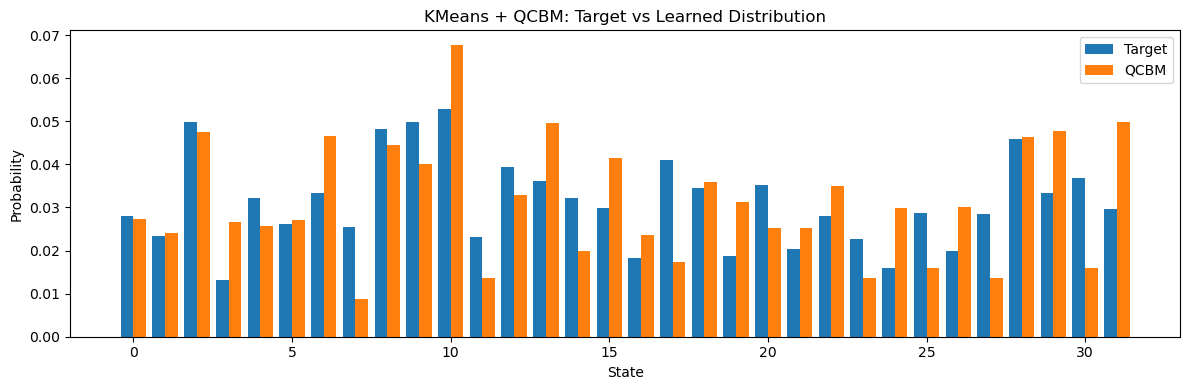

In [16]:
x = np.arange(N_STATES)

plt.figure(figsize=(12, 4))

plt.bar(
    x - 0.2,
    variant_targets[variant_name],
    width=0.4,
    label="Target"
)

plt.bar(
    x + 0.2,
    variant_learned[variant_name],
    width=0.4,
    label="QCBM"
)

plt.xlabel("State")
plt.ylabel("Probability")
plt.title("KMeans + QCBM: Target vs Learned Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "kmeans_qcbm_distribution.png", dpi=300)
plt.show()

In [17]:
generated, generated_df, retriever = retrieve_molecules(
    smiles_list=train_smiles,
    cluster_ids=variant_clusters[variant_name],
    distribution=variant_learned[variant_name],
    method_name=variant_name,
    n_samples=N_GENERATED,
    random_state=SEED
)

variant_generated[variant_name] = generated
variant_generated_tables[variant_name] = generated_df
variant_retrievers[variant_name] = retriever

variant_molecular_metrics.append(
    molecular_quality_summary(
        variant_name,
        generated,
        train_smiles
    )
)

generated_df.head()

,method,smiles
0,KMeans_QCBM,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F
1,KMeans_QCBM,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...
2,KMeans_QCBM,C=CCCCOc1nc2c([nH]1)CCN(c1ccccc1CCCC)C2
3,KMeans_QCBM,CN1CC(Oc2[nH]c3c(c2N2CCCCC2)CCN(c2cncc4ccccc24...
4,KMeans_QCBM,CC(NCc1ccnc(OCC2CCCN2C)n1)=C1CC=NNC1


In [18]:
if RUN_HARDWARE_SUBMISSION:

    kmeans_hw = submit_variant_hardware_job(
        variant_name=variant_name,
        model=kmeans_qcbm,
        backend=backend,
        physical_path=physical_path,
        shots=SHOTS
    )

    variant_hardware_jobs.append(
        {
            "method": variant_name,
            "job_id": kmeans_hw["job_id"],
            "backend": BACKEND_NAME
        }
    )

    print(kmeans_hw["job_info"])

else:

    print("Hardware submission skipped.")

{'variant': 'KMeans_QCBM', 'backend': 'ibm_fez', 'job_id': 'd8ujfptbh0os73er50ug', 'shots': 4096, 'submission_time_sec': 2.5413136999995913, 'physical_path': [0, 1, 2, 3, 16], 'n_qubits': 5, 'n_layers': 3}


# Variant 2 — Chow-Liu + QCBM

This variant injects dependency structure into the molecular representation.

```text
SELFIES token vectors
↓
Pairwise mutual information
↓
Maximum spanning tree
↓
Tree interaction features
↓
KMeans
↓
QCBM
↓
IBM Hardware

In [19]:
start = time.perf_counter()

chowliu_qcbm = ChowLiuQCBM(
    n_clusters=N_CLUSTERS,
    n_qubits=N_QUBITS,
    n_layers=N_LAYERS,
    loss_metric=LOSS_METRIC,
    maxiter=MAXITER
)

chowliu_qcbm.fit(
    X_token
)

runtime = time.perf_counter() - start

variant_name = "ChowLiu_QCBM"

variant_models[variant_name] = chowliu_qcbm
variant_targets[variant_name] = chowliu_qcbm.target_distribution
variant_learned[variant_name] = chowliu_qcbm.learned_distribution
variant_clusters[variant_name] = chowliu_qcbm.cluster_ids

variant_runtime_metrics.append(
    {
        "method": variant_name,
        "runtime_sec": runtime
    }
)

print("Runtime:", runtime)
chowliu_qcbm.summary()

Runtime: 11.223248800000874


{'method': 'ChowLiu+QCBM',
 'clusters': 32,
 'tree_edges': 31,
 'distribution_states': 32}

In [20]:
chowliu_edges = chowliu_qcbm.chowliu_edges()

chowliu_edge_df = pd.DataFrame(
    chowliu_edges,
    columns=[
        "feature_u",
        "feature_v"
    ]
)

save_variant_table(
    chowliu_edge_df,
    "chowliu_qcbm_edges"
)

print("Number of edges:", len(chowliu_edges))
chowliu_edge_df.head()

Number of edges: 31


,feature_u,feature_v
0,0,1
1,1,4
2,1,2
3,1,3
4,1,6


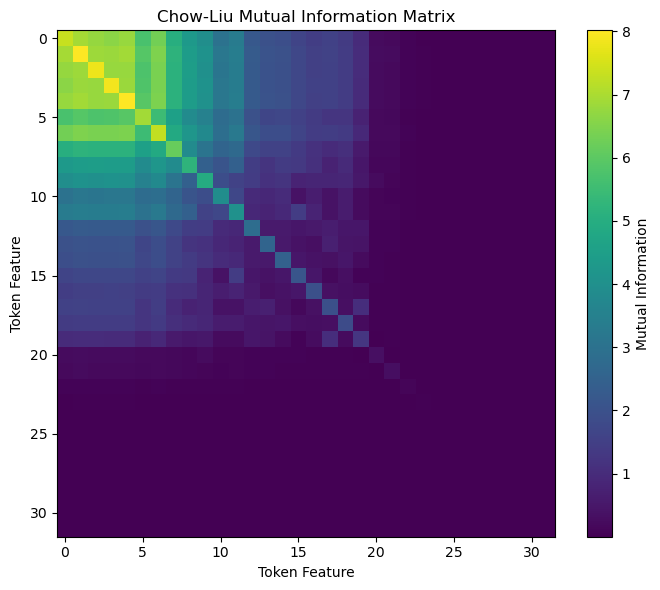

In [21]:
mi_matrix = chowliu_qcbm.chowliu.mi_matrix

plt.figure(figsize=(7, 6))

plt.imshow(
    mi_matrix,
    aspect="auto"
)

plt.colorbar(label="Mutual Information")
plt.title("Chow-Liu Mutual Information Matrix")
plt.xlabel("Token Feature")
plt.ylabel("Token Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "chowliu_mi_matrix.png", dpi=300)
plt.show()

In [22]:
chowliu_distribution_metrics = distribution_report(
    variant_name,
    variant_learned[variant_name],
    variant_targets[variant_name]
)

variant_distribution_metrics.append(
    chowliu_distribution_metrics
)

chowliu_distribution_metrics

{'method': 'ChowLiu_QCBM',
 'KL': 0.025838468423889004,
 'TV': 0.09125294065219587,
 'Fidelity': 0.987020784234962,
 'MMD': 0.0010338751414589455,
 'Sinkhorn': 0.22690913727679998}

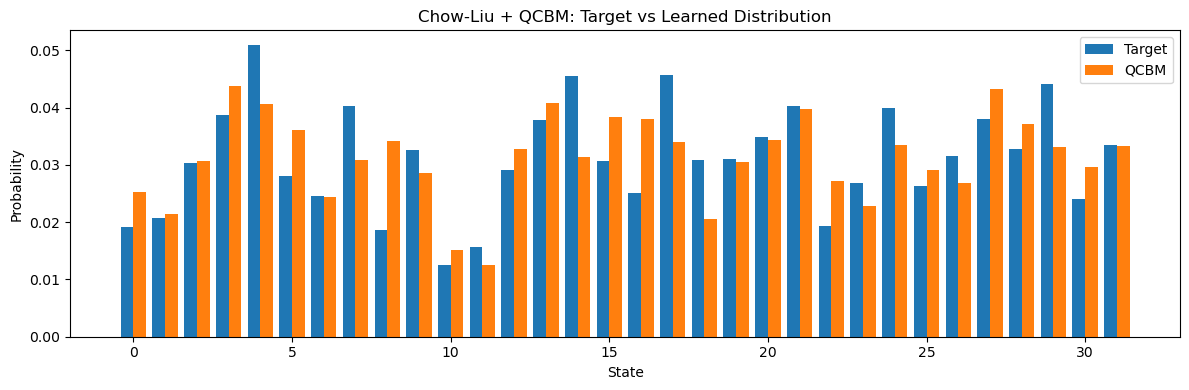

In [23]:
x = np.arange(N_STATES)

plt.figure(figsize=(12, 4))

plt.bar(
    x - 0.2,
    variant_targets[variant_name],
    width=0.4,
    label="Target"
)

plt.bar(
    x + 0.2,
    variant_learned[variant_name],
    width=0.4,
    label="QCBM"
)

plt.xlabel("State")
plt.ylabel("Probability")
plt.title("Chow-Liu + QCBM: Target vs Learned Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "chowliu_qcbm_distribution.png", dpi=300)
plt.show()

In [24]:
generated, generated_df, retriever = retrieve_molecules(
    smiles_list=train_smiles,
    cluster_ids=variant_clusters[variant_name],
    distribution=variant_learned[variant_name],
    method_name=variant_name,
    n_samples=N_GENERATED,
    random_state=SEED
)

variant_generated[variant_name] = generated
variant_generated_tables[variant_name] = generated_df
variant_retrievers[variant_name] = retriever

variant_molecular_metrics.append(
    molecular_quality_summary(
        variant_name,
        generated,
        train_smiles
    )
)

generated_df.head()

,method,smiles
0,ChowLiu_QCBM,CCC(C)COc1nc2c(n1CC)CCN(Cc1nccc3[nH]ncc13)C2
1,ChowLiu_QCBM,FC1CCN2CCCC12Oc1nc(N2CCN3CCCC3C2)c2cnc(Oc3cccc...
2,ChowLiu_QCBM,CCN=C(Cc1cc(N2CCNC(CC)C2)nc(OCC2CCCN2C)n1)c1cn...
3,ChowLiu_QCBM,C=CCCCOc1nc2c(c(-c3cc(N=C)ccc3C)n1)CCN2
4,ChowLiu_QCBM,CCC1CN(c2nc(OCC3CCN3C)c(N)c3c2CCCN3Cc2cncc3ccc...


In [25]:
if RUN_HARDWARE_SUBMISSION:

    chowliu_hw = submit_variant_hardware_job(
        variant_name=variant_name,
        model=chowliu_qcbm,
        backend=backend,
        physical_path=physical_path,
        shots=SHOTS
    )

    variant_hardware_jobs.append(
        {
            "method": variant_name,
            "job_id": chowliu_hw["job_id"],
            "backend": BACKEND_NAME
        }
    )

    print(chowliu_hw["job_info"])

else:

    print("Hardware submission skipped.")

{'variant': 'ChowLiu_QCBM', 'backend': 'ibm_fez', 'job_id': 'd8ujgbtbh0os73er51m0', 'shots': 4096, 'submission_time_sec': 2.4287373999977717, 'physical_path': [0, 1, 2, 3, 16], 'n_qubits': 5, 'n_layers': 3}


In [26]:
pip install torch_geometric

Note: you may need to restart the kernel to use updated packages.


# Variant 3 — GNN Embedding + QCBM

This variant replaces SELFIES token vectors with graph-based molecular embeddings.

```text
SMILES
↓
RDKit molecular graph
↓
GCN embedding
↓
KMeans
↓
QCBM
↓
IBM Hardware

In [27]:
try:
    gnn_encoder_test = GNNEmbeddingEncoder(
        hidden_dim=64,
        embedding_dim=32,
        batch_size=64
    )

    GNN_AVAILABLE = True

except Exception as e:

    GNN_AVAILABLE = False

    print("GNN unavailable:")
    print(e)

GNN_AVAILABLE

True

In [28]:
variant_name = "GNN_QCBM"

if GNN_AVAILABLE:

    start = time.perf_counter()

    gnn_qcbm = GNNQCBM(
        n_clusters=N_CLUSTERS,
        n_qubits=N_QUBITS,
        n_layers=N_LAYERS,
        loss_metric=LOSS_METRIC,
        maxiter=MAXITER,
        embedding_dim=32,
        hidden_dim=64
    )

    gnn_qcbm.fit(
        train_smiles
    )

    runtime = time.perf_counter() - start

    variant_models[variant_name] = gnn_qcbm
    variant_targets[variant_name] = gnn_qcbm.target_distribution
    variant_learned[variant_name] = gnn_qcbm.learned_distribution
    variant_clusters[variant_name] = gnn_qcbm.cluster_ids

    variant_runtime_metrics.append(
        {
            "method": variant_name,
            "runtime_sec": runtime
        }
    )

    print("Runtime:", runtime)
    print(gnn_qcbm.summary())

else:

    print("Skipping GNN_QCBM because torch_geometric is unavailable.")

Runtime: 45.93298209999921
{'method': 'GNN+QCBM', 'fitted': True, 'n_clusters': 32, 'embedding_dim': 32, 'hidden_dim': 64, 'distribution_states': 32}


In [29]:
if GNN_AVAILABLE:

    gnn_stats = gnn_qcbm.embedding_statistics()

    variant_diagnostics["GNN_QCBM"] = gnn_stats

    gnn_stats

else:

    print("Skipped.")

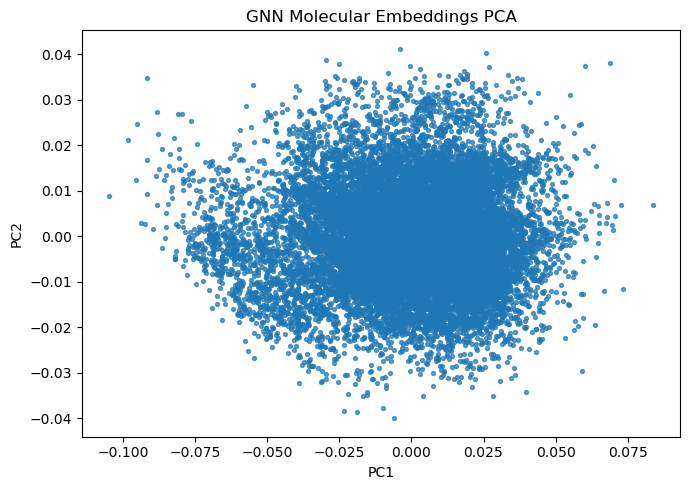

In [30]:
if GNN_AVAILABLE:

    from sklearn.decomposition import PCA

    embeddings_2d = PCA(
        n_components=2,
        random_state=SEED
    ).fit_transform(
        gnn_qcbm.embeddings
    )

    plt.figure(figsize=(7, 5))

    plt.scatter(
        embeddings_2d[:, 0],
        embeddings_2d[:, 1],
        s=8,
        alpha=0.7
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("GNN Molecular Embeddings PCA")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "gnn_embedding_pca.png", dpi=300)
    plt.show()

else:

    print("Skipped.")

In [31]:
if GNN_AVAILABLE:

    gnn_distribution_metrics = distribution_report(
        variant_name,
        variant_learned[variant_name],
        variant_targets[variant_name]
    )

    variant_distribution_metrics.append(
        gnn_distribution_metrics
    )

    generated, generated_df, retriever = retrieve_molecules(
        smiles_list=train_smiles,
        cluster_ids=variant_clusters[variant_name],
        distribution=variant_learned[variant_name],
        method_name=variant_name,
        n_samples=N_GENERATED,
        random_state=SEED
    )

    variant_generated[variant_name] = generated
    variant_generated_tables[variant_name] = generated_df
    variant_retrievers[variant_name] = retriever

    variant_molecular_metrics.append(
        molecular_quality_summary(
            variant_name,
            generated,
            train_smiles
        )
    )

    display(gnn_distribution_metrics)
    display(generated_df.head())

else:

    print("Skipped.")

{'method': 'GNN_QCBM',
 'KL': 0.1171435193699033,
 'TV': 0.179115330750094,
 'Fidelity': 0.9444161277173172,
 'MMD': 0.003961296227520428,
 'Sinkhorn': 0.3944623034988697}

,method,smiles
0,GNN_QCBM,CC1CCN(C)C1Cc1nc2c(c(N3CCCC3)n1)CCN(Cc1c(Cl)cc...
1,GNN_QCBM,Cc1c(C(F)CO)cccc1N1CCc2[nH]c(OC3CCCC3)nc2C1
2,GNN_QCBM,CCC(COCCN(C)C)=NC=C1CCN(c2c(N3CCNCC3)ncc3cccc(...
3,GNN_QCBM,Cn1c(CCc2ccc3[nH]ncc3c2C#N)cnc1OCC1CCCCN1
4,GNN_QCBM,Cn1c(OCC2CN(C3CCCC3)C2)nc2c1CCN(Cc1cccc3c1CCC3...


In [32]:
if RUN_HARDWARE_SUBMISSION and GNN_AVAILABLE:

    gnn_hw = submit_variant_hardware_job(
        variant_name=variant_name,
        model=gnn_qcbm,
        backend=backend,
        physical_path=physical_path,
        shots=SHOTS
    )

    variant_hardware_jobs.append(
        {
            "method": variant_name,
            "job_id": gnn_hw["job_id"],
            "backend": BACKEND_NAME
        }
    )

    print(gnn_hw["job_info"])

else:

    print("GNN hardware submission skipped.")

{'variant': 'GNN_QCBM', 'backend': 'ibm_fez', 'job_id': 'd8ujh9sbp3hs73864gb0', 'shots': 4096, 'submission_time_sec': 2.0182972000038717, 'physical_path': [0, 1, 2, 3, 16], 'n_qubits': 5, 'n_layers': 3}


# Variant 4 — Autoencoder Latent + QCBM

This variant learns a compact nonlinear latent representation before QCBM training.

```text
SELFIES token-count vectors
↓
Autoencoder
↓
Latent vectors
↓
KMeans
↓
QCBM
↓
IBM Hardware

In [33]:
start = time.perf_counter()

latent_qcbm = LatentQCBM(
    latent_dim=32,
    n_clusters=N_CLUSTERS,
    n_qubits=N_QUBITS,
    n_layers=N_LAYERS,
    loss_metric=LOSS_METRIC,
    maxiter=MAXITER,
    random_state=SEED
)

latent_qcbm.fit(
    X_token
)

runtime = time.perf_counter() - start

variant_name = "Latent_QCBM"

variant_models[variant_name] = latent_qcbm
variant_targets[variant_name] = latent_qcbm.target_distribution
variant_learned[variant_name] = latent_qcbm.learned_distribution
variant_clusters[variant_name] = latent_qcbm.cluster_ids

variant_runtime_metrics.append(
    {
        "method": variant_name,
        "runtime_sec": runtime
    }
)

print("Runtime:", runtime)
latent_qcbm.summary()

Runtime: 19.884856299991952


{'method': 'Latent+QCBM',
 'fitted': True,
 'latent_dim': 32,
 'n_clusters': 32,
 'distribution_states': 32}

In [34]:
latent_stats = latent_qcbm.latent_statistics()

reconstruction_error = latent_qcbm.reconstruction_error(
    X_token
)

latent_stats["reconstruction_error"] = reconstruction_error

variant_diagnostics["Latent_QCBM"] = latent_stats

latent_stats

{'n_samples': 19992,
 'latent_dim': 32,
 'mean': -0.03480862081050873,
 'std': 0.2136680632829666,
 'min': -0.6095277070999146,
 'max': 0.5703468322753906,
 'reconstruction_error': 1.4647183193516054e-05}

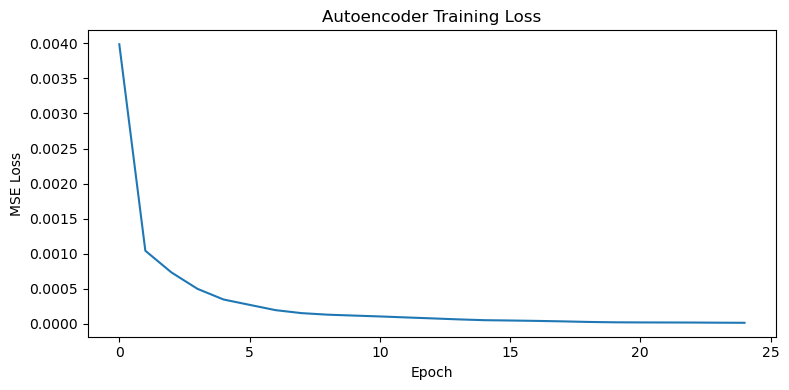

In [35]:
ae_loss = latent_qcbm.autoencoder.training_loss

plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(len(ae_loss)),
    ae_loss
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "autoencoder_training_loss.png", dpi=300)
plt.show()

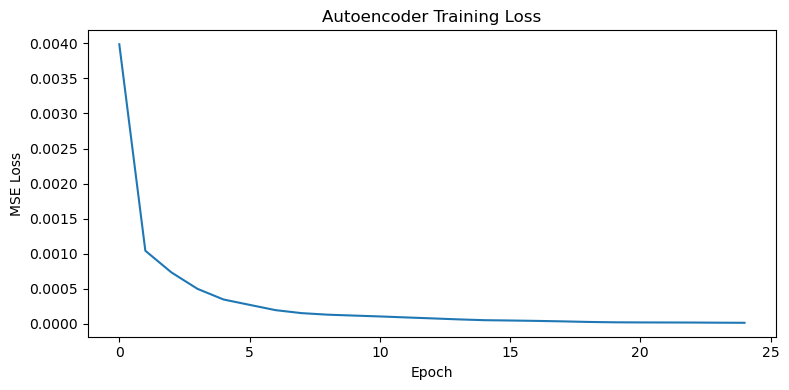

In [36]:
ae_loss = latent_qcbm.autoencoder.training_loss

plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(len(ae_loss)),
    ae_loss
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "autoencoder_training_loss.png", dpi=300)
plt.show()

In [37]:
latent_distribution_metrics = distribution_report(
    variant_name,
    variant_learned[variant_name],
    variant_targets[variant_name]
)

variant_distribution_metrics.append(
    latent_distribution_metrics
)

generated, generated_df, retriever = retrieve_molecules(
    smiles_list=train_smiles,
    cluster_ids=variant_clusters[variant_name],
    distribution=variant_learned[variant_name],
    method_name=variant_name,
    n_samples=N_GENERATED,
    random_state=SEED
)

variant_generated[variant_name] = generated
variant_generated_tables[variant_name] = generated_df
variant_retrievers[variant_name] = retriever

variant_molecular_metrics.append(
    molecular_quality_summary(
        variant_name,
        generated,
        train_smiles
    )
)

display(latent_distribution_metrics)
display(generated_df.head())

{'method': 'Latent_QCBM',
 'KL': 0.026996008128995795,
 'TV': 0.09052823856608302,
 'Fidelity': 0.9867105887224132,
 'MMD': 0.001189886910993672,
 'Sinkhorn': 0.16563917864388028}

,method,smiles
0,Latent_QCBM,CCNc1c(F)cccc1-c1ncc2c(N3CCN4CCC4C3)nc(OCC3CCC...
1,Latent_QCBM,CN1CCCC1Oc1nc(N2CCN3CCC3C2)c2cnc(-c3ccc4cn[nH]...
2,Latent_QCBM,COCC(F)(F)c1cccc(N2CCc3c(nc(OCC4CC5CCC4C5)n3C)...
3,Latent_QCBM,C=CN(Cc1c[nH]c(OCC2CCCOC2)n1)c1ccc(Cl)cn1
4,Latent_QCBM,C=CCCCOC1=NC=C(C)C(Nc2cccc3[nH]ncc23)C1


In [38]:
latent_distribution_metrics = distribution_report(
    variant_name,
    variant_learned[variant_name],
    variant_targets[variant_name]
)

variant_distribution_metrics.append(
    latent_distribution_metrics
)

generated, generated_df, retriever = retrieve_molecules(
    smiles_list=train_smiles,
    cluster_ids=variant_clusters[variant_name],
    distribution=variant_learned[variant_name],
    method_name=variant_name,
    n_samples=N_GENERATED,
    random_state=SEED
)

variant_generated[variant_name] = generated
variant_generated_tables[variant_name] = generated_df
variant_retrievers[variant_name] = retriever

variant_molecular_metrics.append(
    molecular_quality_summary(
        variant_name,
        generated,
        train_smiles
    )
)

display(latent_distribution_metrics)
display(generated_df.head())

{'method': 'Latent_QCBM',
 'KL': 0.026996008128995795,
 'TV': 0.09052823856608302,
 'Fidelity': 0.9867105887224132,
 'MMD': 0.001189886910993672,
 'Sinkhorn': 0.16563917864388028}

,method,smiles
0,Latent_QCBM,CCNc1c(F)cccc1-c1ncc2c(N3CCN4CCC4C3)nc(OCC3CCC...
1,Latent_QCBM,CN1CCCC1Oc1nc(N2CCN3CCC3C2)c2cnc(-c3ccc4cn[nH]...
2,Latent_QCBM,COCC(F)(F)c1cccc(N2CCc3c(nc(OCC4CC5CCC4C5)n3C)...
3,Latent_QCBM,C=CN(Cc1c[nH]c(OCC2CCCOC2)n1)c1ccc(Cl)cn1
4,Latent_QCBM,C=CCCCOC1=NC=C(C)C(Nc2cccc3[nH]ncc23)C1


In [39]:
if RUN_HARDWARE_SUBMISSION:

    latent_hw = submit_variant_hardware_job(
        variant_name=variant_name,
        model=latent_qcbm,
        backend=backend,
        physical_path=physical_path,
        shots=SHOTS
    )

    variant_hardware_jobs.append(
        {
            "method": variant_name,
            "job_id": latent_hw["job_id"],
            "backend": BACKEND_NAME
        }
    )

    print(latent_hw["job_info"])

else:

    print("Hardware submission skipped.")

{'variant': 'Latent_QCBM', 'backend': 'ibm_fez', 'job_id': 'd8ujiidposuc738q9e0g', 'shots': 4096, 'submission_time_sec': 2.4063480000040727, 'physical_path': [0, 1, 2, 3, 16], 'n_qubits': 5, 'n_layers': 3}


# Variant 5 — RL + QCBM

This section uses an optimized state-level reward feedback loop.

The previous version was slow because it computed molecule-level rewards for thousands of generated molecules and repeatedly checked novelty against the full training set.

Updated pipeline:

```text
Initial KMeans-QCBM
↓
Sample quantum states
↓
Fast cluster-based reconstruction
↓
Score unique molecules only
↓
Aggregate reward per quantum state
↓
Build reward-weighted target distribution
↓
Train reinforced QCBM
↓
Retrieve final molecules
↓
Evaluate

In [40]:
def build_cluster_index(
    smiles_list,
    cluster_ids
):
    cluster_map = {}

    for smi, cluster in zip(
        smiles_list,
        cluster_ids
    ):

        cluster = int(cluster)

        if cluster not in cluster_map:
            cluster_map[cluster] = []

        cluster_map[cluster].append(
            smi
        )

    return cluster_map


def fast_reconstruct_from_states(
    sampled_states,
    cluster_map,
    random_state=SEED
):
    rng = np.random.default_rng(
        random_state
    )

    generated = []

    used_states = []

    available_states = list(
        cluster_map.keys()
    )

    for state in sampled_states:

        state = int(state)

        candidates = cluster_map.get(
            state,
            None
        )

        if not candidates:

            fallback_state = int(
                rng.choice(
                    available_states
                )
            )

            candidates = cluster_map[
                fallback_state
            ]

            used_states.append(
                fallback_state
            )

        else:

            used_states.append(
                state
            )

        generated.append(
            rng.choice(
                candidates
            )
        )

    return generated, np.array(
        used_states,
        dtype=int
    )


def canonical_set_fast(
    smiles_list
):
    from rdkit import Chem

    out = set()

    for smi in smiles_list:

        try:

            mol = Chem.MolFromSmiles(
                smi
            )

            if mol is None:
                continue

            out.add(
                Chem.MolToSmiles(
                    mol,
                    canonical=True
                )
            )

        except Exception:
            continue

    return out


def safe_float(
    value,
    default=0.0
):
    try:

        if value is None:
            return default

        value = float(value)

        if np.isnan(value):
            return default

        return value

    except Exception:

        return default


def cached_molecule_reward_table(
    generated_smiles,
    training_canonical_set,
    max_unique=None
):
    from rdkit import Chem

    unique_smiles = list(
        dict.fromkeys(
            generated_smiles
        )
    )

    if max_unique is not None:
        unique_smiles = unique_smiles[
            :max_unique
        ]

    rows = []
    reward_cache = {}

    for i, smi in enumerate(
        unique_smiles
    ):

        try:

            mol = Chem.MolFromSmiles(
                smi
            )

            if mol is None:

                qed = 0.0
                sa = 10.0
                syba = 0.0
                novelty = 0.0
                canonical = None

            else:

                canonical = Chem.MolToSmiles(
                    mol,
                    canonical=True
                )

                qed = safe_float(
                    qed_score(
                        smi
                    ),
                    default=0.0
                )

                sa = safe_float(
                    sa_score(
                        smi
                    ),
                    default=10.0
                )

                syba = safe_float(
                    syba_score_smiles(
                        smi
                    ),
                    default=0.0
                )

                novelty = (
                    0.0
                    if canonical in training_canonical_set
                    else 1.0
                )

            sa_easy = (
                1.0
                -
                min(
                    max(
                        sa,
                        1.0
                    ),
                    10.0
                )
                /
                10.0
            )

            reward = (
                1.00 * qed
                +
                0.50 * sa_easy
                +
                0.25 * np.tanh(
                    syba / 10.0
                )
                +
                1.00 * novelty
            )

            reward_cache[smi] = float(
                reward
            )

            rows.append(
                {
                    "SMILES": smi,
                    "Canonical": canonical,
                    "QED": qed,
                    "SA": sa,
                    "SYBA": syba,
                    "Novelty": novelty,
                    "Reward": float(reward)
                }
            )

        except Exception:

            reward_cache[smi] = 0.0

            rows.append(
                {
                    "SMILES": smi,
                    "Canonical": None,
                    "QED": 0.0,
                    "SA": 10.0,
                    "SYBA": 0.0,
                    "Novelty": 0.0,
                    "Reward": 0.0
                }
            )

        if (i + 1) % 250 == 0:

            print(
                f"Scored {i + 1:,} unique molecules..."
            )

    reward_df = pd.DataFrame(
        rows
    )

    return reward_df, reward_cache


def state_reward_distribution(
    sampled_states,
    generated_smiles,
    reward_cache,
    n_states=N_STATES,
    temperature=1.0,
    smoothing=1e-3
):
    state_rewards = np.zeros(
        n_states,
        dtype=float
    )

    state_counts = np.zeros(
        n_states,
        dtype=float
    )

    for state, smi in zip(
        sampled_states,
        generated_smiles
    ):

        state = int(
            state
        )

        reward = reward_cache.get(
            smi,
            0.0
        )

        state_rewards[state] += reward
        state_counts[state] += 1.0

    avg_rewards = np.zeros(
        n_states,
        dtype=float
    )

    mask = state_counts > 0

    avg_rewards[mask] = (
        state_rewards[mask]
        /
        state_counts[mask]
    )

    avg_rewards = avg_rewards - np.min(
        avg_rewards
    )

    weights = np.exp(
        avg_rewards
        /
        max(
            temperature,
            1e-6
        )
    )

    counts_component = (
        state_counts
        +
        smoothing
    )

    weighted = (
        weights
        *
        counts_component
    )

    if weighted.sum() == 0:

        return np.ones(
            n_states
        ) / n_states

    return weighted / weighted.sum()


def rl_state_reward_table(
    sampled_states,
    generated_smiles,
    reward_cache,
    n_states=N_STATES
):
    rows = []

    for state in range(
        n_states
    ):

        rewards = [
            reward_cache.get(
                smi,
                0.0
            )
            for st, smi in zip(
                sampled_states,
                generated_smiles
            )
            if int(st) == state
        ]

        if len(rewards) == 0:

            rows.append(
                {
                    "state": state,
                    "count": 0,
                    "mean_reward": 0.0,
                    "max_reward": 0.0
                }
            )

        else:

            rows.append(
                {
                    "state": state,
                    "count": len(rewards),
                    "mean_reward": float(
                        np.mean(
                            rewards
                        )
                    ),
                    "max_reward": float(
                        np.max(
                            rewards
                        )
                    )
                }
            )

    return pd.DataFrame(
        rows
    )

In [41]:
def build_cluster_index(
    smiles_list,
    cluster_ids
):
    cluster_map = {}

    for smi, cluster in zip(
        smiles_list,
        cluster_ids
    ):

        cluster = int(cluster)

        if cluster not in cluster_map:
            cluster_map[cluster] = []

        cluster_map[cluster].append(
            smi
        )

    return cluster_map


def fast_reconstruct_from_states(
    sampled_states,
    cluster_map,
    random_state=SEED
):
    rng = np.random.default_rng(
        random_state
    )

    generated = []

    used_states = []

    available_states = list(
        cluster_map.keys()
    )

    for state in sampled_states:

        state = int(state)

        candidates = cluster_map.get(
            state,
            None
        )

        if not candidates:

            fallback_state = int(
                rng.choice(
                    available_states
                )
            )

            candidates = cluster_map[
                fallback_state
            ]

            used_states.append(
                fallback_state
            )

        else:

            used_states.append(
                state
            )

        generated.append(
            rng.choice(
                candidates
            )
        )

    return generated, np.array(
        used_states,
        dtype=int
    )


def canonical_set_fast(
    smiles_list
):
    from rdkit import Chem

    out = set()

    for smi in smiles_list:

        try:

            mol = Chem.MolFromSmiles(
                smi
            )

            if mol is None:
                continue

            out.add(
                Chem.MolToSmiles(
                    mol,
                    canonical=True
                )
            )

        except Exception:
            continue

    return out


def safe_float(
    value,
    default=0.0
):
    try:

        if value is None:
            return default

        value = float(value)

        if np.isnan(value):
            return default

        return value

    except Exception:

        return default


def cached_molecule_reward_table(
    generated_smiles,
    training_canonical_set,
    max_unique=None
):
    from rdkit import Chem

    unique_smiles = list(
        dict.fromkeys(
            generated_smiles
        )
    )

    if max_unique is not None:
        unique_smiles = unique_smiles[
            :max_unique
        ]

    rows = []
    reward_cache = {}

    for i, smi in enumerate(
        unique_smiles
    ):

        try:

            mol = Chem.MolFromSmiles(
                smi
            )

            if mol is None:

                qed = 0.0
                sa = 10.0
                syba = 0.0
                novelty = 0.0
                canonical = None

            else:

                canonical = Chem.MolToSmiles(
                    mol,
                    canonical=True
                )

                qed = safe_float(
                    qed_score(
                        smi
                    ),
                    default=0.0
                )

                sa = safe_float(
                    sa_score(
                        smi
                    ),
                    default=10.0
                )

                syba = safe_float(
                    syba_score_smiles(
                        smi
                    ),
                    default=0.0
                )

                novelty = (
                    0.0
                    if canonical in training_canonical_set
                    else 1.0
                )

            sa_easy = (
                1.0
                -
                min(
                    max(
                        sa,
                        1.0
                    ),
                    10.0
                )
                /
                10.0
            )

            reward = (
                1.00 * qed
                +
                0.50 * sa_easy
                +
                0.25 * np.tanh(
                    syba / 10.0
                )
                +
                1.00 * novelty
            )

            reward_cache[smi] = float(
                reward
            )

            rows.append(
                {
                    "SMILES": smi,
                    "Canonical": canonical,
                    "QED": qed,
                    "SA": sa,
                    "SYBA": syba,
                    "Novelty": novelty,
                    "Reward": float(reward)
                }
            )

        except Exception:

            reward_cache[smi] = 0.0

            rows.append(
                {
                    "SMILES": smi,
                    "Canonical": None,
                    "QED": 0.0,
                    "SA": 10.0,
                    "SYBA": 0.0,
                    "Novelty": 0.0,
                    "Reward": 0.0
                }
            )

        if (i + 1) % 250 == 0:

            print(
                f"Scored {i + 1:,} unique molecules..."
            )

    reward_df = pd.DataFrame(
        rows
    )

    return reward_df, reward_cache


def state_reward_distribution(
    sampled_states,
    generated_smiles,
    reward_cache,
    n_states=N_STATES,
    temperature=1.0,
    smoothing=1e-3
):
    state_rewards = np.zeros(
        n_states,
        dtype=float
    )

    state_counts = np.zeros(
        n_states,
        dtype=float
    )

    for state, smi in zip(
        sampled_states,
        generated_smiles
    ):

        state = int(
            state
        )

        reward = reward_cache.get(
            smi,
            0.0
        )

        state_rewards[state] += reward
        state_counts[state] += 1.0

    avg_rewards = np.zeros(
        n_states,
        dtype=float
    )

    mask = state_counts > 0

    avg_rewards[mask] = (
        state_rewards[mask]
        /
        state_counts[mask]
    )

    avg_rewards = avg_rewards - np.min(
        avg_rewards
    )

    weights = np.exp(
        avg_rewards
        /
        max(
            temperature,
            1e-6
        )
    )

    counts_component = (
        state_counts
        +
        smoothing
    )

    weighted = (
        weights
        *
        counts_component
    )

    if weighted.sum() == 0:

        return np.ones(
            n_states
        ) / n_states

    return weighted / weighted.sum()


def rl_state_reward_table(
    sampled_states,
    generated_smiles,
    reward_cache,
    n_states=N_STATES
):
    rows = []

    for state in range(
        n_states
    ):

        rewards = [
            reward_cache.get(
                smi,
                0.0
            )
            for st, smi in zip(
                sampled_states,
                generated_smiles
            )
            if int(st) == state
        ]

        if len(rewards) == 0:

            rows.append(
                {
                    "state": state,
                    "count": 0,
                    "mean_reward": 0.0,
                    "max_reward": 0.0
                }
            )

        else:

            rows.append(
                {
                    "state": state,
                    "count": len(rewards),
                    "mean_reward": float(
                        np.mean(
                            rewards
                        )
                    ),
                    "max_reward": float(
                        np.max(
                            rewards
                        )
                    )
                }
            )

    return pd.DataFrame(
        rows
    )

In [42]:
start = time.perf_counter()

rl_base = RLQCBM()

rl_base.fit(
    latent_vectors=X_token,
    smiles_list=train_smiles
)

runtime_fit = time.perf_counter() - start

variant_name = "RL_QCBM"

print("Initial RL-QCBM fit time:", runtime_fit)
rl_base.summary()

Initial RL-QCBM fit time: 5.340852199995425


{'method': 'RL+QCBM',
 'reward_weight_syba': 1.0,
 'reward_weight_qed': 1.0,
 'reward_weight_novelty': 1.0,
 'fitted': True}

In [43]:
start = time.perf_counter()

RL_REWARD_SAMPLES = min(
    1024,
    N_GENERATED
)

rl_sampled_states = rl_base.qcbm_model.sample_states(
    n_samples=RL_REWARD_SAMPLES,
    random_state=SEED
)

cluster_map = build_cluster_index(
    smiles_list=train_smiles,
    cluster_ids=rl_base.cluster_ids
)

rl_generated, rl_used_states = fast_reconstruct_from_states(
    sampled_states=rl_sampled_states,
    cluster_map=cluster_map,
    random_state=SEED
)

runtime_reconstruction = time.perf_counter() - start

print("Sampled states:", len(rl_sampled_states))
print("Generated molecules:", len(rl_generated))
print("Used states:", len(rl_used_states))
print("Unique molecules:", len(set(rl_generated)))
print("Reconstruction runtime:", runtime_reconstruction)

Sampled states: 1024
Generated molecules: 1024
Used states: 1024
Unique molecules: 1000
Reconstruction runtime: 0.15278430000762455


In [44]:
start = time.perf_counter()

training_canonical_set = canonical_set_fast(
    train_smiles
)

rl_reward_df, rl_reward_cache = cached_molecule_reward_table(
    generated_smiles=rl_generated,
    training_canonical_set=training_canonical_set,
    max_unique=None
)

runtime_reward = time.perf_counter() - start

print("Reward rows:", len(rl_reward_df))
print("Reward runtime:", runtime_reward)

rl_reward_df.head()

Scored 250 unique molecules...
Scored 500 unique molecules...
Scored 750 unique molecules...
Scored 1,000 unique molecules...
Reward rows: 1000
Reward runtime: 13.337051700000302


,SMILES,Canonical,QED,SA,SYBA,Novelty,Reward
0,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F,0.543344,3.228768,33.695302,0.0,1.131314
1,CN1CCCC1COc1nc2c(c(N3CCN(C)C(Cc4cncc5cccc(O)c4...,CN1CCCC1COc1nc2c(c(N3CCN(C)C(Cc4cncc5cccc(O)c4...,0.525504,4.040156,0.551975,0.0,0.837281
2,CCC1CCN(c2nc(OCC34CCCN3CCC4)nc3c(F)c(F)ncc23)C1,CCC1CCN(c2nc(OCC34CCCN3CCC4)nc3c(F)c(F)ncc23)C1,0.712052,3.791956,19.270631,0.0,1.262078
3,CN1CC(Oc2[nH]c3c(c2N2CCCCC2)CCN(c2cncc4ccccc24...,CN1CC(Oc2[nH]c3c(c2N2CCCCC2)CCN(c2cncc4ccccc24...,0.374567,4.336405,6.558624,0.0,0.801647
4,CC1CCN1CCOc1ncc2c(n1)CN(C=C(F)CC(F)(F)F)CC2,CC1CCN1CCOc1ncc2c(n1)CN(C=C(F)CC(F)(F)F)CC2,0.716182,3.919444,3.739749,0.0,1.109576


In [45]:
rl_reinforced_target = state_reward_distribution(
    sampled_states=rl_used_states,
    generated_smiles=rl_generated,
    reward_cache=rl_reward_cache,
    n_states=N_STATES,
    temperature=1.0,
    smoothing=1e-3
)

print("Distribution shape:", rl_reinforced_target.shape)
print("Mass:", rl_reinforced_target.sum())
print("Min:", rl_reinforced_target.min())
print("Max:", rl_reinforced_target.max())

rl_state_reward_df = rl_state_reward_table(
    sampled_states=rl_used_states,
    generated_smiles=rl_generated,
    reward_cache=rl_reward_cache,
    n_states=N_STATES
)

rl_state_reward_df.head()

Distribution shape: (32,)
Mass: 1.0
Min: 0.009680076336501234
Max: 0.04663922616974207


,state,count,mean_reward,max_reward
0,0,31,1.263773,1.491530
1,1,35,1.118947,1.352362
2,2,21,1.083585,1.500926
3,3,33,1.200050,1.482237
4,4,42,1.207270,1.481658


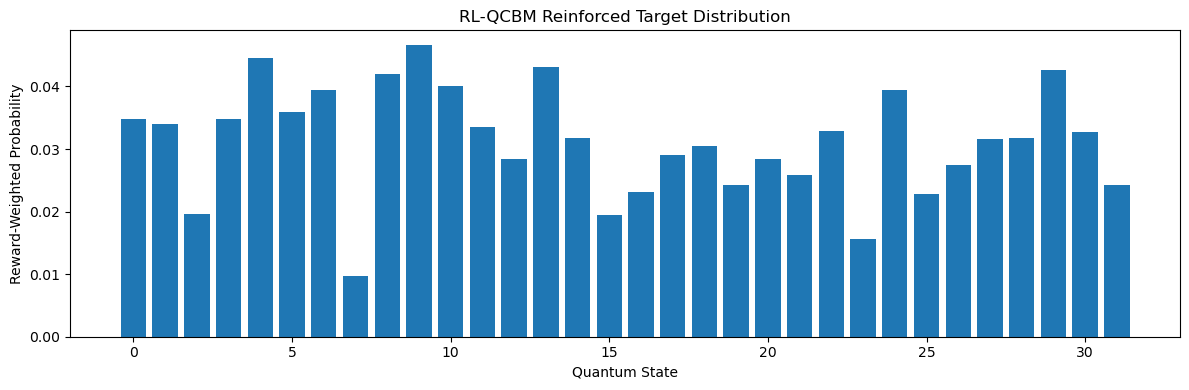

In [46]:
plt.figure(
    figsize=(12, 4)
)

plt.bar(
    np.arange(
        N_STATES
    ),
    rl_reinforced_target
)

plt.xlabel(
    "Quantum State"
)

plt.ylabel(
    "Reward-Weighted Probability"
)

plt.title(
    "RL-QCBM Reinforced Target Distribution"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "rl_qcbm_reinforced_target_distribution.png",
    dpi=300
)

plt.show()

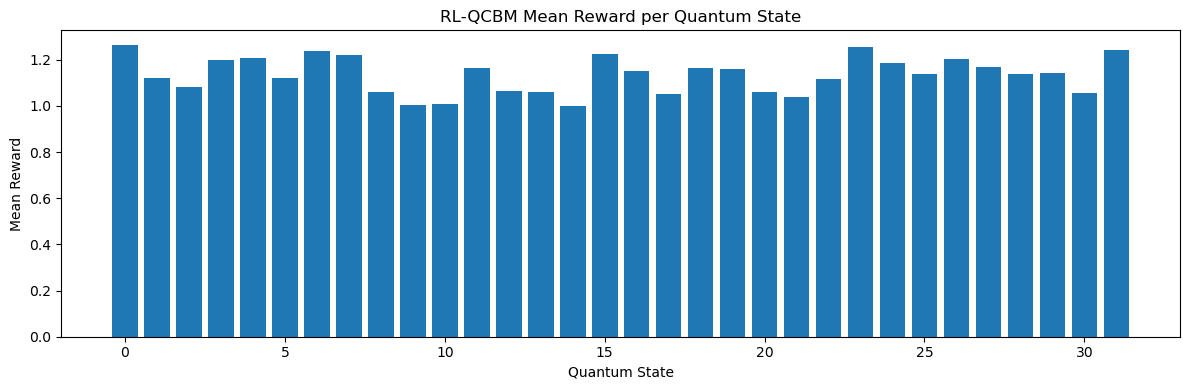

In [47]:
plt.figure(
    figsize=(12, 4)
)

plt.bar(
    rl_state_reward_df["state"],
    rl_state_reward_df["mean_reward"]
)

plt.xlabel(
    "Quantum State"
)

plt.ylabel(
    "Mean Reward"
)

plt.title(
    "RL-QCBM Mean Reward per Quantum State"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "rl_qcbm_state_rewards.png",
    dpi=300
)

plt.show()

In [48]:
start = time.perf_counter()

RL_MAXITER = min(
    MAXITER,
    100
)

rl_reinforced_qcbm = QCBM(
    n_qubits=N_QUBITS,
    n_layers=N_LAYERS,
    loss_metric=LOSS_METRIC,
    maxiter=RL_MAXITER
)

rl_reinforced_qcbm.fit(
    rl_reinforced_target
)

rl_learned_distribution = rl_reinforced_qcbm.probabilities()

runtime_reinforced_training = time.perf_counter() - start

runtime_rl_total = (
    runtime_fit
    +
    runtime_reconstruction
    +
    runtime_reward
    +
    runtime_reinforced_training
)

print("Reinforced QCBM training runtime:", runtime_reinforced_training)
print("RL total runtime:", runtime_rl_total)
print("Best loss:", rl_reinforced_qcbm.best_loss())

Reinforced QCBM training runtime: 0.4494945999904303
RL total runtime: 19.28018279999378
Best loss: 0.0011720121711568377


In [49]:
class RLQCBMHardwareAdapter:
    """
    Adapter so submit_variant_hardware_job()
    can access model.qcbm.parameters().
    """

    def __init__(
        self,
        qcbm
    ):
        self.qcbm = qcbm


rl_adapter = RLQCBMHardwareAdapter(
    rl_reinforced_qcbm
)

variant_models[variant_name] = rl_adapter

variant_targets[variant_name] = rl_reinforced_target

variant_learned[variant_name] = rl_learned_distribution

variant_clusters[variant_name] = rl_base.cluster_ids

variant_runtime_metrics.append(
    {
        "method": variant_name,
        "runtime_sec": runtime_rl_total
    }
)

In [50]:
rl_distribution_metrics = distribution_report(
    variant_name,
    variant_learned[variant_name],
    variant_targets[variant_name]
)

variant_distribution_metrics.append(
    rl_distribution_metrics
)

rl_distribution_metrics

{'method': 'RL_QCBM',
 'KL': 0.027497393943319536,
 'TV': 0.09276010405755533,
 'Fidelity': 0.9860767948271674,
 'MMD': 0.0011720121711568377,
 'Sinkhorn': 0.25717785367094664}

In [51]:
generated, generated_df, retriever = retrieve_molecules(
    smiles_list=train_smiles,
    cluster_ids=variant_clusters[variant_name],
    distribution=variant_learned[variant_name],
    method_name=variant_name,
    n_samples=N_GENERATED,
    random_state=SEED
)

variant_generated[variant_name] = generated

variant_generated_tables[variant_name] = generated_df

variant_retrievers[variant_name] = retriever

generated_df.head()

,method,smiles
0,RL_QCBM,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F
1,RL_QCBM,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...
2,RL_QCBM,C=CCCCOc1nc2c([nH]1)CCN(c1ccccc1CCCC)C2
3,RL_QCBM,CN1CC(Oc2[nH]c3c(c2N2CCCCC2)CCN(c2cncc4ccccc24...
4,RL_QCBM,CC1CCN1CCOc1ncc2c(n1)CN(C=C(F)CC(F)(F)F)CC2


In [52]:
rl_molecular_summary = molecular_quality_summary(
    variant_name,
    generated,
    train_smiles
)

variant_molecular_metrics.append(
    rl_molecular_summary
)

rl_molecular_summary

{'method': 'RL_QCBM',
 'generated': 4096,
 'validity': 1.0,
 'validity_percent': 100.0,
 'uniqueness': 0.901611328125,
 'uniqueness_percent': 90.1611328125,
 'novelty': 0.0,
 'novelty_percent': 0.0,
 'mean_qed': 0.6035196249827341,
 'median_qed': 0.5930722650516783,
 'mean_sa': 3.7697354637459686,
 'median_sa': 3.799063195951839,
 'mean_syba': 22.82295725355,
 'median_syba': 18.771277469231116}

In [53]:
rl_reward_df.to_csv(
    TABLES_DIR / "rl_qcbm_reward_table.csv",
    index=False
)

rl_state_reward_df.to_csv(
    TABLES_DIR / "rl_qcbm_state_reward_table.csv",
    index=False
)

pd.DataFrame(
    {
        "state": np.arange(N_STATES),
        "reinforced_probability": rl_reinforced_target,
        "learned_probability": rl_learned_distribution
    }
).to_csv(
    TABLES_DIR / "rl_qcbm_reinforced_distribution.csv",
    index=False
)

print("RL-QCBM tables saved.")

RL-QCBM tables saved.


In [54]:
if RUN_HARDWARE_SUBMISSION:

    rl_hw = submit_variant_hardware_job(
        variant_name=variant_name,
        model=rl_adapter,
        backend=backend,
        physical_path=physical_path,
        shots=SHOTS
    )

    variant_hardware_jobs.append(
        {
            "method": variant_name,
            "job_id": rl_hw["job_id"],
            "backend": BACKEND_NAME
        }
    )

    print(
        rl_hw["job_info"]
    )

else:

    print(
        "Hardware submission skipped."
    )

{'variant': 'RL_QCBM', 'backend': 'ibm_fez', 'job_id': 'd8ujj85bh0os73er55f0', 'shots': 4096, 'submission_time_sec': 2.4362526000040816, 'physical_path': [0, 1, 2, 3, 16], 'n_qubits': 5, 'n_layers': 3}


# Unified Variant Benchmark

The following tables compare all QCBM variants using:

```text
Distribution metrics:
KL, TV, Fidelity, MMD, Sinkhorn

Molecular metrics:
Validity, Uniqueness, Novelty, QED, SA, SYBA

Runtime:
Wall-clock runtime for statevector training and retrieval.

In [55]:
distribution_metrics_df = pd.DataFrame(
    variant_distribution_metrics
)

distribution_metrics_df = distribution_metrics_df.sort_values(
    by=["KL", "TV"],
    ascending=True
).reset_index(drop=True)

save_variant_table(
    distribution_metrics_df,
    "variant_distribution_metrics"
)

distribution_metrics_df

,method,KL,TV,Fidelity,MMD,Sinkhorn
0,ChowLiu_QCBM,0.025838,0.091253,0.987021,0.001034,0.226909
1,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639
2,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639
3,RL_QCBM,0.027497,0.092760,0.986077,0.001172,0.257178
4,KMeans_QCBM,0.085178,0.158898,0.960010,0.002452,0.231462
5,GNN_QCBM,0.117144,0.179115,0.944416,0.003961,0.394462


In [56]:
molecular_metrics_df = pd.DataFrame(
    variant_molecular_metrics
)

molecular_metrics_df = molecular_metrics_df.sort_values(
    by=["mean_qed", "uniqueness"],
    ascending=False
).reset_index(drop=True)

save_variant_table(
    molecular_metrics_df,
    "variant_molecular_metrics"
)

molecular_metrics_df

,method,generated,validity,validity_percent,uniqueness,uniqueness_percent,novelty,novelty_percent,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba
0,Latent_QCBM,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574
1,Latent_QCBM,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574
2,KMeans_QCBM,4096,1.0,100.0,0.897461,89.746094,0.0,0.0,0.604596,0.593610,3.764090,3.791190,22.887647,18.872033
3,RL_QCBM,4096,1.0,100.0,0.901611,90.161133,0.0,0.0,0.603520,0.593072,3.769735,3.799063,22.822957,18.771277
4,ChowLiu_QCBM,4096,1.0,100.0,0.906494,90.649414,0.0,0.0,0.601809,0.586567,3.773194,3.802808,22.266524,18.668256
5,GNN_QCBM,4096,1.0,100.0,0.880859,88.085938,0.0,0.0,0.599354,0.594312,3.760017,3.777748,22.607872,19.097123


In [57]:
runtime_metrics_df = pd.DataFrame(
    variant_runtime_metrics
)

save_variant_table(
    runtime_metrics_df,
    "variant_runtime_metrics"
)

runtime_metrics_df

,method,runtime_sec
0,KMeans_QCBM,10.478867
1,ChowLiu_QCBM,11.223249
2,GNN_QCBM,45.932982
3,Latent_QCBM,19.884856
4,RL_QCBM,19.280183


In [58]:
final_benchmark_df = (
    distribution_metrics_df
    .merge(
        molecular_metrics_df,
        on="method",
        how="left"
    )
    .merge(
        runtime_metrics_df,
        on="method",
        how="left"
    )
)

final_benchmark_df = final_benchmark_df.sort_values(
    by=["KL", "TV"],
    ascending=True
).reset_index(drop=True)

save_variant_table(
    final_benchmark_df,
    "variant_final_benchmark"
)

final_benchmark_df

,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,validity_percent,uniqueness,uniqueness_percent,novelty,novelty_percent,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,runtime_sec
0,ChowLiu_QCBM,0.025838,0.091253,0.987021,0.001034,0.226909,4096,1.0,100.0,0.906494,90.649414,0.0,0.0,0.601809,0.586567,3.773194,3.802808,22.266524,18.668256,11.223249
1,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574,19.884856
2,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574,19.884856
3,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574,19.884856
4,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574,19.884856
5,RL_QCBM,0.027497,0.092760,0.986077,0.001172,0.257178,4096,1.0,100.0,0.901611,90.161133,0.0,0.0,0.603520,0.593072,3.769735,3.799063,22.822957,18.771277,19.280183
6,KMeans_QCBM,0.085178,0.158898,0.960010,0.002452,0.231462,4096,1.0,100.0,0.897461,89.746094,0.0,0.0,0.604596,0.593610,3.764090,3.791190,22.887647,18.872033,10.478867
7,GNN_QCBM,0.117144,0.179115,0.944416,0.003961,0.394462,4096,1.0,100.0,0.880859,88.085938,0.0,0.0,0.599354,0.594312,3.760017,3.777748,22.607872,19.097123,45.932982


In [59]:
for method_name, df_gen in variant_generated_tables.items():

    output_path = RESULTS_DIR / f"generated_{method_name}.csv"

    df_gen.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

Saved: D:\QCBM Molecular Augmentation Lite\results\qcbm_variants\generated_KMeans_QCBM.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\qcbm_variants\generated_ChowLiu_QCBM.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\qcbm_variants\generated_GNN_QCBM.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\qcbm_variants\generated_Latent_QCBM.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\qcbm_variants\generated_RL_QCBM.csv


In [60]:
hardware_jobs_df = pd.DataFrame(
    variant_hardware_jobs
)

hardware_jobs_path = HARDWARE_DIR / "variant_hardware_jobs.csv"

hardware_jobs_df.to_csv(
    hardware_jobs_path,
    index=False
)

hardware_jobs_df

,method,job_id,backend
0,KMeans_QCBM,d8ujfptbh0os73er50ug,ibm_fez
1,ChowLiu_QCBM,d8ujgbtbh0os73er51m0,ibm_fez
2,GNN_QCBM,d8ujh9sbp3hs73864gb0,ibm_fez
3,Latent_QCBM,d8ujiidposuc738q9e0g,ibm_fez
4,RL_QCBM,d8ujj85bh0os73er55f0,ibm_fez


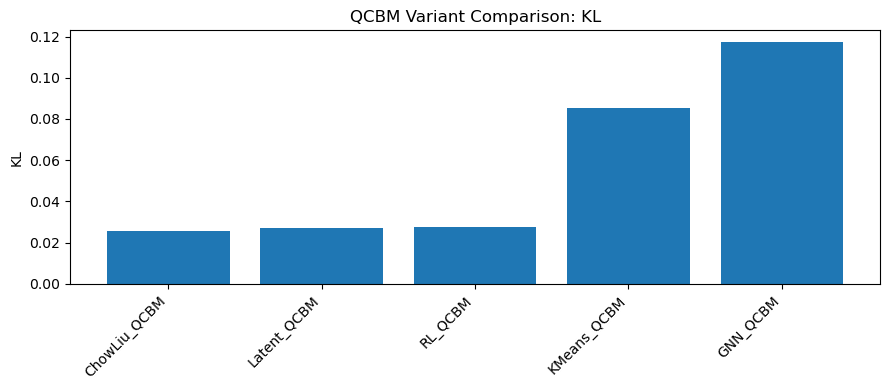

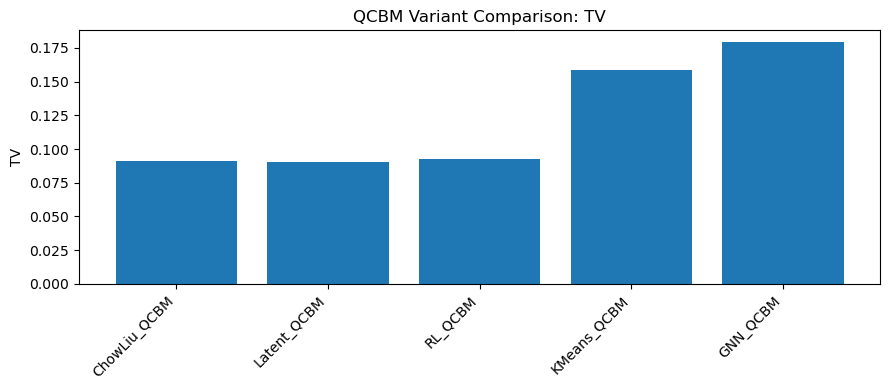

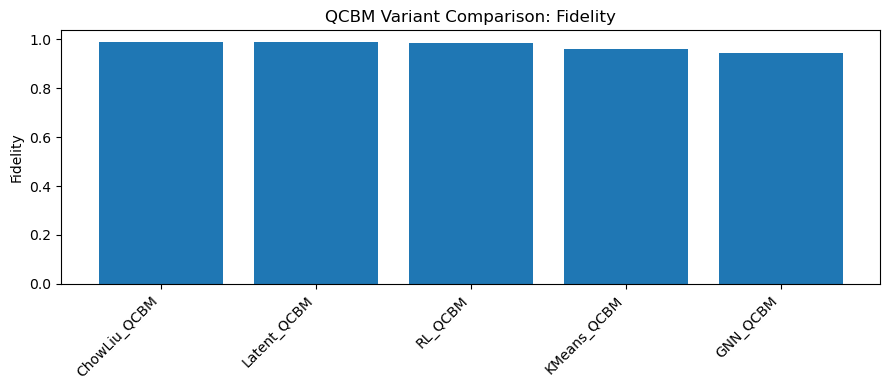

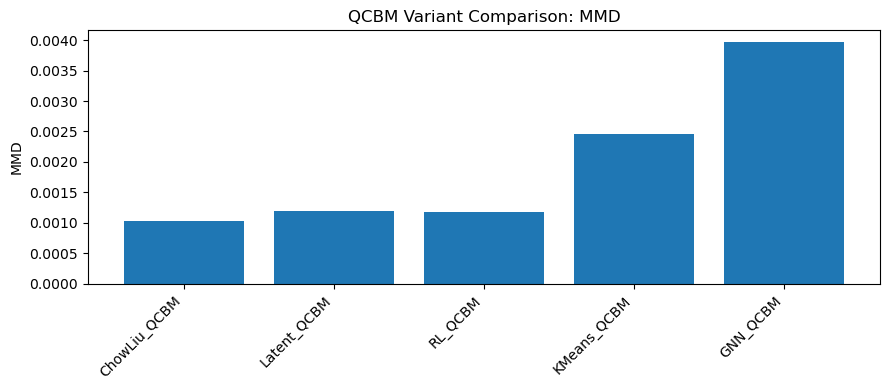

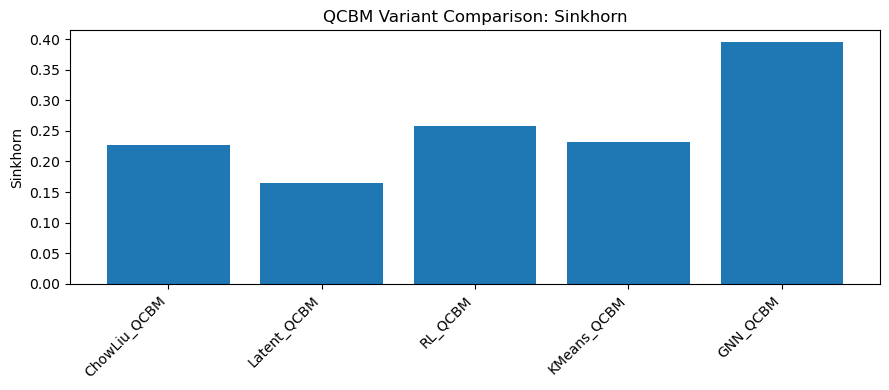

In [61]:
for metric in ["KL", "TV", "Fidelity", "MMD", "Sinkhorn"]:

    plt.figure(figsize=(9, 4))

    plt.bar(
        final_benchmark_df["method"],
        final_benchmark_df[metric]
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.ylabel(metric)
    plt.title(f"QCBM Variant Comparison: {metric}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"variant_{metric}.png", dpi=300)
    plt.show()

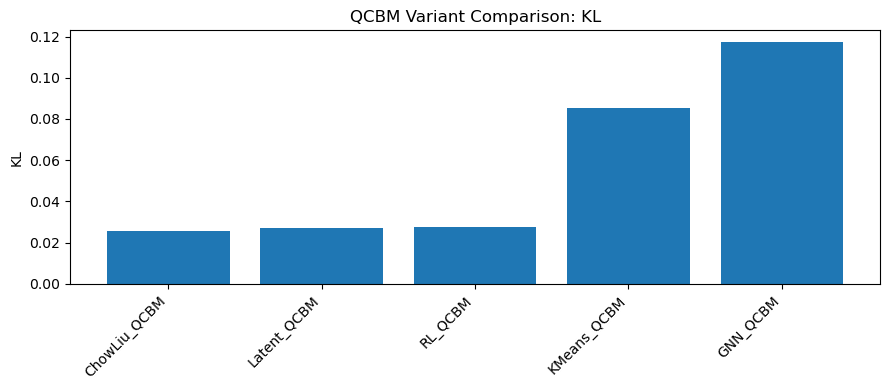

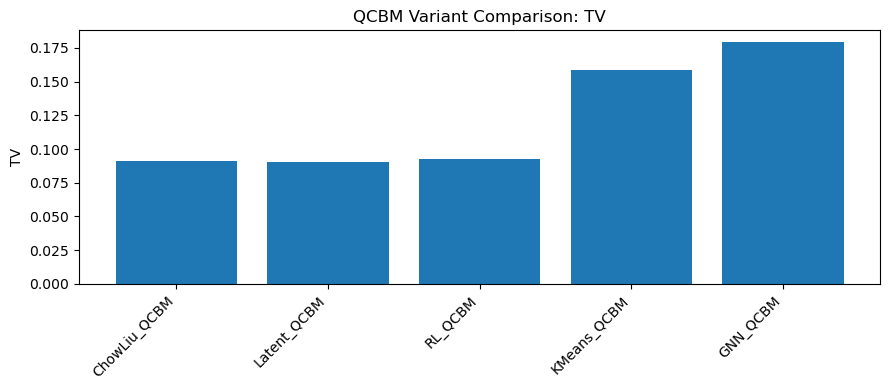

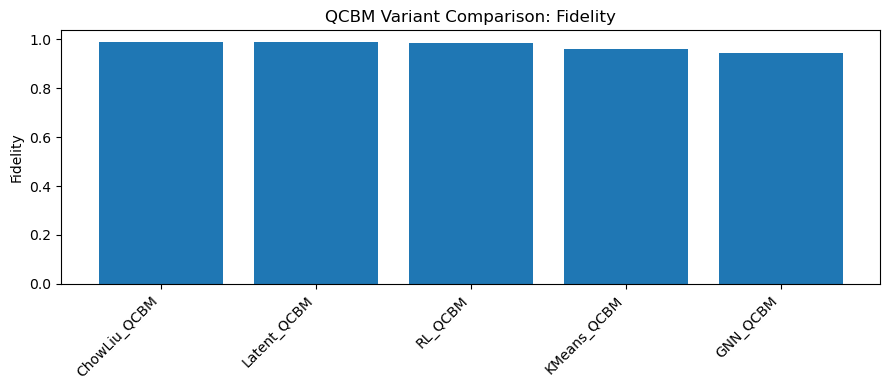

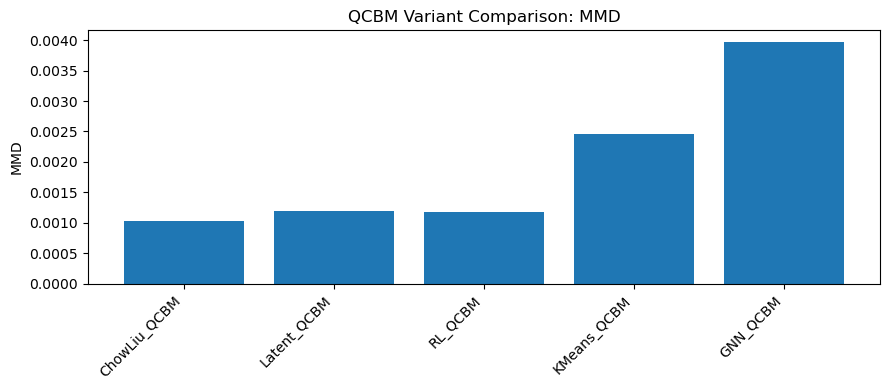

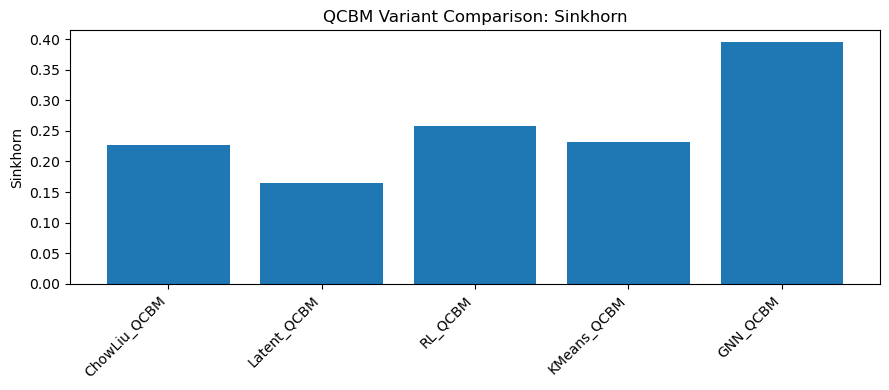

In [62]:
for metric in ["KL", "TV", "Fidelity", "MMD", "Sinkhorn"]:

    plt.figure(figsize=(9, 4))

    plt.bar(
        final_benchmark_df["method"],
        final_benchmark_df[metric]
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.ylabel(metric)
    plt.title(f"QCBM Variant Comparison: {metric}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"variant_{metric}.png", dpi=300)
    plt.show()

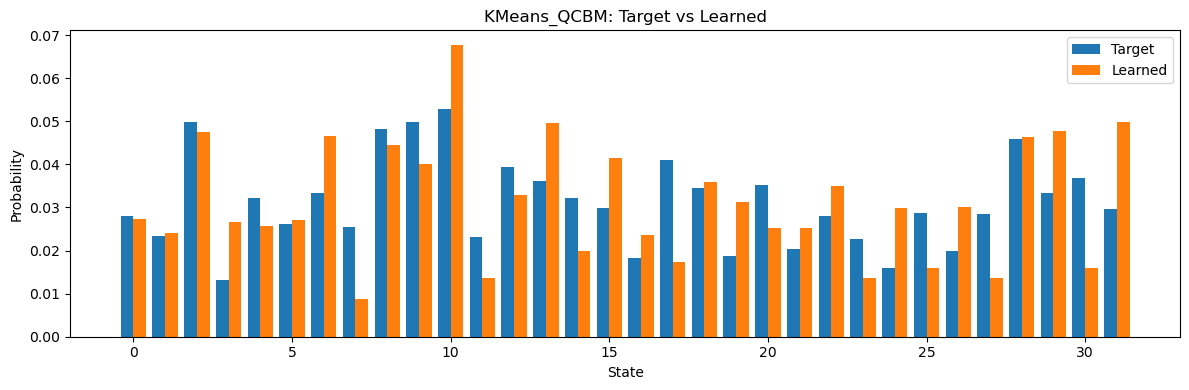

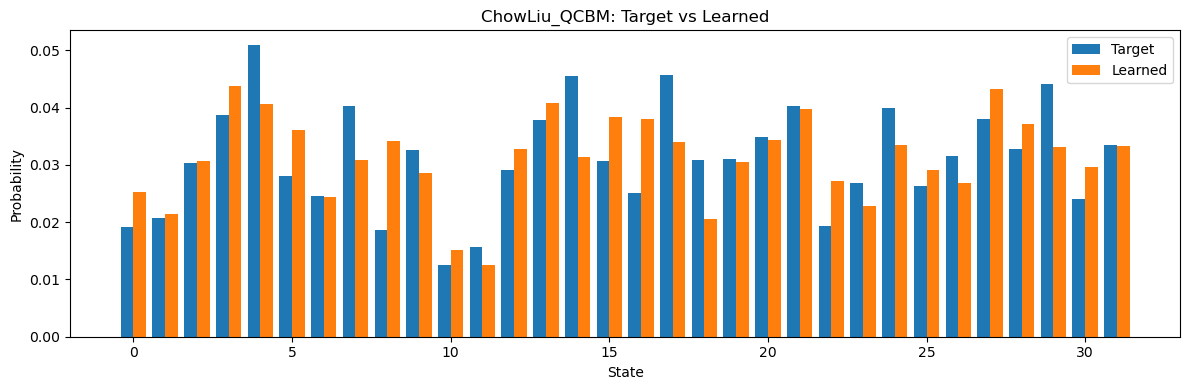

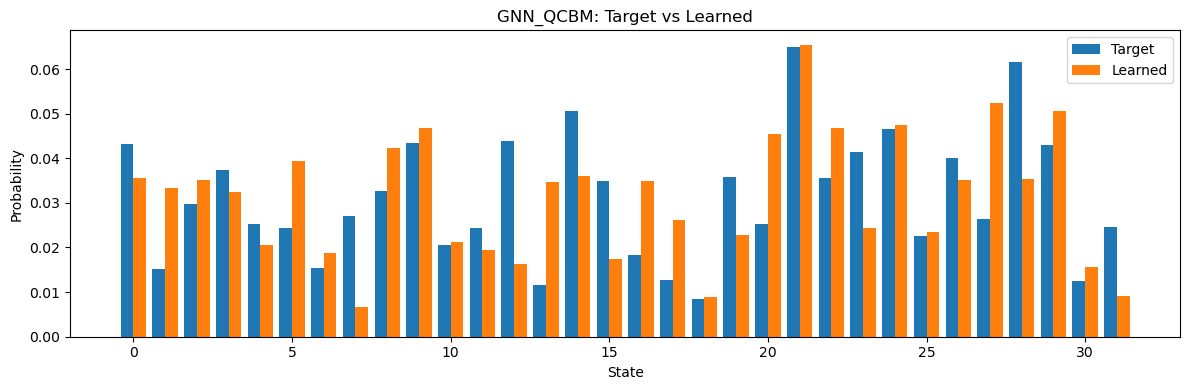

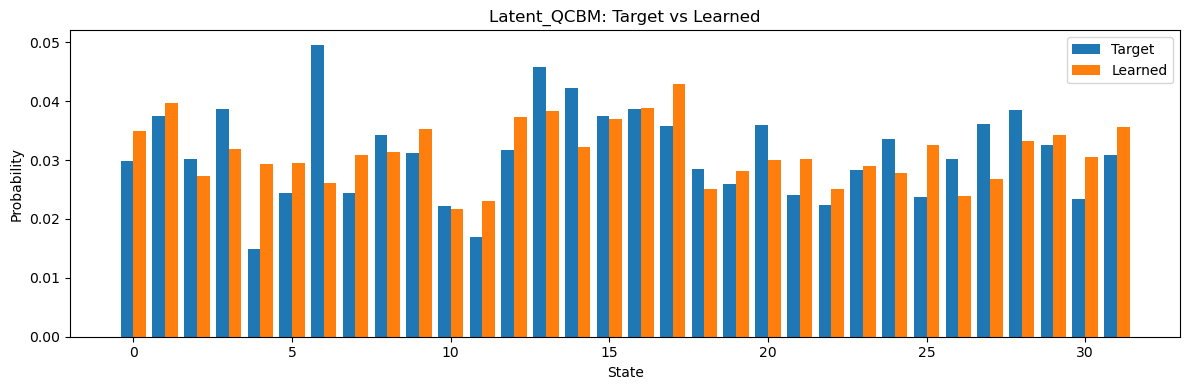

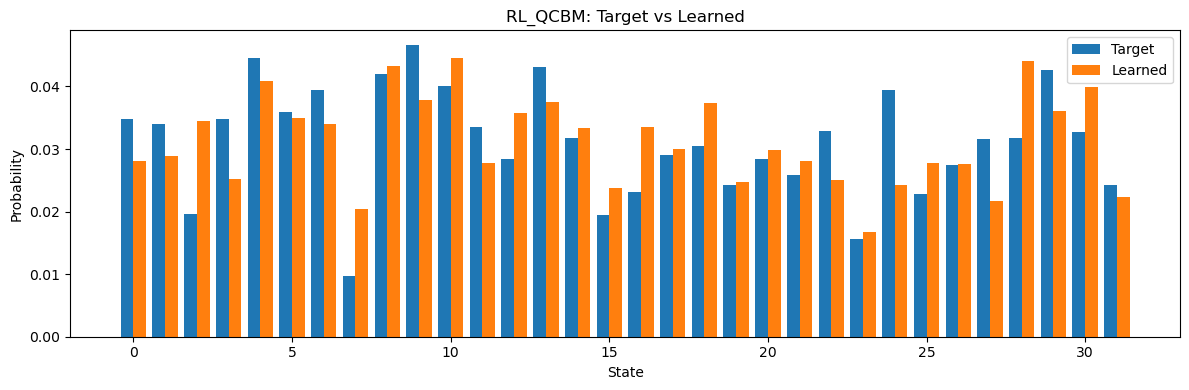

In [63]:
for method_name in variant_learned:

    plt.figure(figsize=(12, 4))

    x = np.arange(N_STATES)

    plt.bar(
        x - 0.2,
        variant_targets[method_name],
        width=0.4,
        label="Target"
    )

    plt.bar(
        x + 0.2,
        variant_learned[method_name],
        width=0.4,
        label="Learned"
    )

    plt.xlabel("State")
    plt.ylabel("Probability")
    plt.title(f"{method_name}: Target vs Learned")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f"{method_name}_target_vs_learned.png",
        dpi=300
    )
    plt.show()

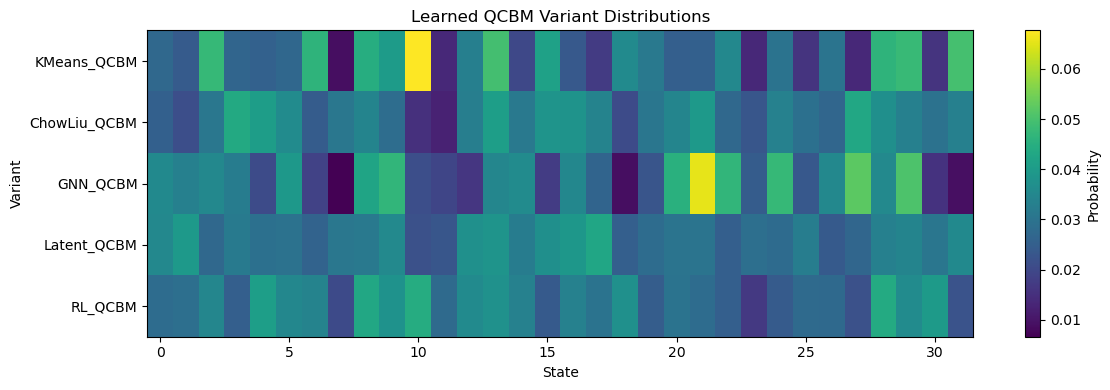

In [64]:
heatmap_methods = list(
    variant_learned.keys()
)

heatmap_matrix = np.vstack(
    [
        variant_learned[m]
        for m in heatmap_methods
    ]
)

plt.figure(figsize=(12, 4))

plt.imshow(
    heatmap_matrix,
    aspect="auto"
)

plt.yticks(
    np.arange(len(heatmap_methods)),
    heatmap_methods
)

plt.xlabel("State")
plt.ylabel("Variant")
plt.colorbar(label="Probability")
plt.title("Learned QCBM Variant Distributions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "variant_distribution_heatmap.png", dpi=300)
plt.show()

In [65]:
all_score_tables = []

for method_name, smiles in variant_generated.items():

    qed_df = qed_dataframe(
        smiles
    )

    sa_df = sa_dataframe(
        smiles
    )

    syba_df = pd.DataFrame(
        {
            "SMILES": smiles,
            "SYBA": [
                syba_score_smiles(s)
                for s in smiles
            ]
        }
    )

    score_df = (
        qed_df
        .merge(sa_df, on="SMILES", how="left")
        .merge(syba_df, on="SMILES", how="left")
    )

    score_df["method"] = method_name

    all_score_tables.append(
        score_df
    )

variant_score_df = pd.concat(
    all_score_tables,
    ignore_index=True
)

variant_score_df.to_csv(
    TABLES_DIR / "variant_molecule_scores.csv",
    index=False
)

variant_score_df.head()

,SMILES,QED,SA_Score,SYBA,method
0,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F,0.543344,3.228768,33.695302,KMeans_QCBM
1,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569,KMeans_QCBM
2,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569,KMeans_QCBM
3,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569,KMeans_QCBM
4,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569,KMeans_QCBM


In [66]:
top_molecules_all = []

for method_name in variant_score_df["method"].unique():

    subset = variant_score_df[
        variant_score_df["method"] == method_name
    ]

    top = (
        subset
        .dropna()
        .sort_values(
            by=["QED", "SYBA"],
            ascending=False
        )
        .head(20)
        .copy()
    )

    top_molecules_all.append(
        top
    )

top_molecules_df = pd.concat(
    top_molecules_all,
    ignore_index=True
)

top_molecules_df.to_csv(
    TABLES_DIR / "variant_top_molecules.csv",
    index=False
)

top_molecules_df

,SMILES,QED,SA_Score,SYBA,method
0,CC1CN(C)CC1Oc1ncc(O)c(-c2ccccc2F)n1,0.942734,3.543729,10.775216,KMeans_QCBM
1,CCN1Cc2nc(OCC3CCCN3C)ccc2-c2[nH]ccc21,0.942656,3.559938,19.189777,KMeans_QCBM
2,COC1CNC(Cc2cnc(-c3ccccc3C)c(F)c2)C1,0.941817,3.257243,13.721172,KMeans_QCBM
3,Cc1ccccc1N1CCCc2[nH]c(OCC3CCC=N3)nc21,0.941219,3.774259,16.787729,KMeans_QCBM
4,Cc1cccc(N2Cc3ccc(CC4CCCN4C)nc3C2)c1O,0.941049,3.159405,22.724778,KMeans_QCBM
...,...,...,...,...,...
95,CN1CCC(F)(F)C1COc1ncc(-c2ccccc2O)cn1,0.937758,3.443818,0.548635,RL_QCBM
96,CC(C)c1cccc2c1N(C)CC2COc1nc2c([nH]1)CCC2,0.937110,3.673169,15.886165,RL_QCBM
97,CC1CC1COc1nc(N2CCNCC2)c2cccc(F)c2n1,0.937106,3.365154,16.460146,RL_QCBM
98,CC1CC(COc2nc3c([nH]2)CCN(c2ccccc2)C3)C1C,0.936938,3.903135,6.277349,RL_QCBM


# Research Interpretation

This notebook compares five hybrid QCBM variants under a fixed 5-qubit / 32-state constraint.

## KMeans + QCBM

This is the strongest reference baseline because it directly follows the original QCBM molecular augmentation pipeline.

## Chow-Liu + QCBM

This tests whether explicit pairwise dependency structure improves molecular-state learning.

A strong Chow-Liu result means the token dependencies encode chemically meaningful structure before quantum learning.

## GNN + QCBM

This tests whether graph topology improves QCBM target distributions compared with SELFIES token vectors.

If GNN-QCBM improves KL, TV, or Fidelity, the result supports graph-based quantum molecular representation learning.

## Latent + QCBM

This tests whether nonlinear compression through an autoencoder produces a smoother and easier-to-learn quantum distribution.

## RL + QCBM

This introduces feedback from chemical reward into the target distribution.

The RL variant is no longer purely distribution-matching. It biases the quantum model toward chemically preferred regions of molecular space.

In [68]:
# ============================================================
# Remove duplicate entries (keep latest run)
# ============================================================

distribution_metrics_df = (
    distribution_metrics_df
    .drop_duplicates(
        subset="method",
        keep="last"
    )
    .sort_values("method")
    .reset_index(drop=True)
)

molecular_metrics_df = (
    molecular_metrics_df
    .drop_duplicates(
        subset="method",
        keep="last"
    )
    .sort_values("method")
    .reset_index(drop=True)
)

runtime_metrics_df = (
    runtime_metrics_df
    .drop_duplicates(
        subset="method",
        keep="last"
    )
    .sort_values("method")
    .reset_index(drop=True)
)

hardware_jobs_df = (
    hardware_jobs_df
    .drop_duplicates(
        subset="method",
        keep="last"
    )
    .sort_values("method")
    .reset_index(drop=True)
)

# Rebuild final benchmark after removing duplicates
final_benchmark_df = (
    distribution_metrics_df
    .merge(
        molecular_metrics_df,
        on="method",
        how="outer"
    )
    .merge(
        runtime_metrics_df,
        on="method",
        how="left"
    )
    .sort_values("method")
    .reset_index(drop=True)
)

print("=" * 80)
print("05 QCBM VARIANTS NOTEBOOK COMPLETE")
print("=" * 80)

print("\nNumber of Variants")
print(f"Distribution : {len(distribution_metrics_df)}")
print(f"Molecular    : {len(molecular_metrics_df)}")
print(f"Runtime      : {len(runtime_metrics_df)}")
print(f"Hardware     : {len(hardware_jobs_df)}")

print("\nDistribution Benchmark")
display(distribution_metrics_df)

print("\nMolecular Benchmark")
display(molecular_metrics_df)

print("\nFinal Benchmark")
display(final_benchmark_df)

print("\nHardware Jobs")
display(hardware_jobs_df)

print("\nResults directory:")
print(RESULTS_DIR)

05 QCBM VARIANTS NOTEBOOK COMPLETE

Number of Variants
Distribution : 5
Molecular    : 5
Runtime      : 5
Hardware     : 5

Distribution Benchmark


,method,KL,TV,Fidelity,MMD,Sinkhorn
0,ChowLiu_QCBM,0.025838,0.091253,0.987021,0.001034,0.226909
1,GNN_QCBM,0.117144,0.179115,0.944416,0.003961,0.394462
2,KMeans_QCBM,0.085178,0.158898,0.960010,0.002452,0.231462
3,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639
4,RL_QCBM,0.027497,0.092760,0.986077,0.001172,0.257178



Molecular Benchmark


,method,generated,validity,validity_percent,uniqueness,uniqueness_percent,novelty,novelty_percent,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba
0,ChowLiu_QCBM,4096,1.0,100.0,0.906494,90.649414,0.0,0.0,0.601809,0.586567,3.773194,3.802808,22.266524,18.668256
1,GNN_QCBM,4096,1.0,100.0,0.880859,88.085938,0.0,0.0,0.599354,0.594312,3.760017,3.777748,22.607872,19.097123
2,KMeans_QCBM,4096,1.0,100.0,0.897461,89.746094,0.0,0.0,0.604596,0.593610,3.764090,3.791190,22.887647,18.872033
3,Latent_QCBM,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574
4,RL_QCBM,4096,1.0,100.0,0.901611,90.161133,0.0,0.0,0.603520,0.593072,3.769735,3.799063,22.822957,18.771277



Final Benchmark


,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,validity_percent,uniqueness,uniqueness_percent,novelty,novelty_percent,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,runtime_sec
0,ChowLiu_QCBM,0.025838,0.091253,0.987021,0.001034,0.226909,4096,1.0,100.0,0.906494,90.649414,0.0,0.0,0.601809,0.586567,3.773194,3.802808,22.266524,18.668256,11.223249
1,GNN_QCBM,0.117144,0.179115,0.944416,0.003961,0.394462,4096,1.0,100.0,0.880859,88.085938,0.0,0.0,0.599354,0.594312,3.760017,3.777748,22.607872,19.097123,45.932982
2,KMeans_QCBM,0.085178,0.158898,0.960010,0.002452,0.231462,4096,1.0,100.0,0.897461,89.746094,0.0,0.0,0.604596,0.593610,3.764090,3.791190,22.887647,18.872033,10.478867
3,Latent_QCBM,0.026996,0.090528,0.986711,0.001190,0.165639,4096,1.0,100.0,0.905762,90.576172,0.0,0.0,0.606991,0.599163,3.767657,3.783668,22.422228,18.816574,19.884856
4,RL_QCBM,0.027497,0.092760,0.986077,0.001172,0.257178,4096,1.0,100.0,0.901611,90.161133,0.0,0.0,0.603520,0.593072,3.769735,3.799063,22.822957,18.771277,19.280183



Hardware Jobs


,method,job_id,backend
0,ChowLiu_QCBM,d8ujgbtbh0os73er51m0,ibm_fez
1,GNN_QCBM,d8ujh9sbp3hs73864gb0,ibm_fez
2,KMeans_QCBM,d8ujfptbh0os73er50ug,ibm_fez
3,Latent_QCBM,d8ujiidposuc738q9e0g,ibm_fez
4,RL_QCBM,d8ujj85bh0os73er55f0,ibm_fez



Results directory:
D:\QCBM Molecular Augmentation Lite\results\qcbm_variants


# Notebook Outputs

This notebook produced:

```text
results/qcbm_variants/

├── tables/
│   ├── variant_distribution_metrics.csv
│   ├── variant_molecular_metrics.csv
│   ├── variant_runtime_metrics.csv
│   ├── variant_final_benchmark.csv
│   ├── variant_molecule_scores.csv
│   └── variant_top_molecules.csv
│
├── figures/
│   ├── kmeans_qcbm_distribution.png
│   ├── chowliu_mi_matrix.png
│   ├── gnn_embedding_pca.png
│   ├── autoencoder_training_loss.png
│   ├── latent_qcbm_pca.png
│   ├── rl_qcbm_reward_distribution.png
│   ├── variant_distribution_heatmap.png
│   └── variant metric plots
│
├── hardware_jobs/
│   ├── KMeans_QCBM/
│   ├── ChowLiu_QCBM/
│   ├── GNN_QCBM/
│   ├── Latent_QCBM/
│   ├── RL_QCBM/
│   └── variant_hardware_jobs.csv
│
├── generated_KMeans_QCBM.csv
├── generated_ChowLiu_QCBM.csv
├── generated_GNN_QCBM.csv
├── generated_Latent_QCBM.csv
└── generated_RL_QCBM.csv